# State-function decomposition in the LAI-aridity bins (as of 2026-11-23)

Each bin's contribution to the difference in domain-mean ET between a dataset (m) and the obs reference (r = `obs_pooled`), from `scripts/decompose_state_function.py` (`decomposition.decompose_binned`). With $a_b$ the fraction of the common land area in bin $b$ (the occupancy, `p` in the code), $f_b$ the bin-mean ET, both of the obs reference, and $\Delta$ the dataset minus the reference:

| term | per bin | in the code |
|---|---|---|
| $\Delta a_b \cdot f_b$ | $(a^m_b - a_b)\, f_b$ | `STATE` |
| $a_b \cdot \Delta f_b$ | $a_b\, (f^m_b - f_b)$ | `FUNCTION` |
| $\Delta a_b \cdot \Delta f_b$ | $(a^m_b - a_b)(f^m_b - f_b)$ | `INTERACTION` |

Their sum in each bin is $a^m_b f^m_b - a_b f_b$, and summed over the bins of the common support S (bins with ET in both m and r; NaN elsewhere) they are the terms of `decomp_vs_obs`, with STATE + FUNCTION + INTERACTION = `E_mm - E_rr`. Each value is a bin's share of the domain-mean ET difference [W m$^{-2}$].

**Data families:** `[lsmobs, cmip, trendy_s3, fppe, ippe, lens]` against `obs_pooled` (obs only in S1.2: its sources share LAI, P and Rn, so their $\Delta a_b = 0$)

### Main
1. **Terms of each pooled family**
    1. The three terms and their sum on one color scale
    2. Each term on its own color scale
2. **Spread across members**
    1. Standard deviation of each term across each family's members
3. **Distribution of the terms across the bins**
    1. Histogram of each term over the bins of each pooled family
    2. Histogram of each term over the bins of each member

### Supplement
1. **Panel plots for all models/members for each data family**
    1. $\Delta a_b \cdot f_b$
    2. $a_b \cdot \Delta f_b$
    3. $\Delta a_b \cdot \Delta f_b$
    4. Histograms of the terms

In [1]:
import textwrap

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

import etunc.config as cfg
import etunc.plotting as plotting

## 0. Preamble

### 0.1. Settings

In [2]:
RUN_ID = "r38cf3df"  # config/runs/aw_bins15.yml
_run = cfg.run_settings(RUN_ID)  # raises if RUN_ID is not registered

AREA_WEIGHTED = _run["binning"]["area_weighted"]
BIN_VARIABLE = _run["binning"]["bin_variable"]
EDGES = "pooled_all"
REFERENCE = "obs_pooled"  # obs reference of every term

# decompose_state_function.py needs a land-area weighted run of ET
if not AREA_WEIGHTED or BIN_VARIABLE != "et":
    raise ValueError(f"RUN_ID {RUN_ID} is not a land-area weighted run of et")

TIME_SLICE = slice(*_run["prep"]["time_slice"])
N_YBINS = _run["binning"]["n_ybins"]  # LAI
N_XBINS = _run["binning"]["n_xbins"]  # AI

FAMILIES = ["obs", "lsmobs", "cmip", "trendy_s3", "fppe", "ippe", "lens"]
DECOMP_FAMILIES = [f for f in FAMILIES if f != "obs"]  # the families compared with obs

print(f"RUN_ID: {RUN_ID}")
print(f"AREA_WEIGHTED: {AREA_WEIGHTED}")
print(f"BIN_VARIABLE: {BIN_VARIABLE}")
print(f"TIME_SLICE: {TIME_SLICE}")
print(f"N_YBINS: {N_YBINS}")
print(f"N_XBINS: {N_XBINS}")
print(f"REFERENCE: {REFERENCE}")

RUN_ID: r38cf3df
AREA_WEIGHTED: True
BIN_VARIABLE: et
TIME_SLICE: slice('2001-01', '2014-12', None)
N_YBINS: 15
N_XBINS: 15
REFERENCE: obs_pooled


In [3]:
DPI = 80

FAMILY_KWARGS = {
    "labels": {
        "obs": "OBS",
        "lsmobs": "ERA5/GLDAS",
        "cmip": "CMIP6",
        "fppe": "CESM2 FPPE",
        "ippe": "CESM2 IPPE",
        "lens": "CESM2 LENS",
        "trendy_s3": "TRENDY",
    },
    "colors": {
        "obs": "#000000",
        "lsmobs": "#989898",
        "cmip": "#EF476F",
        "fppe": "#118AB2",
        "ippe": "#09546D",
        "lens": "#FFD166",
        "trendy_s3": "#06D6A0",
    },
}

# The terms of decompose_binned, labelled in the notation of this notebook (a: land fraction, f: bin-mean ET)
TERMS = {
    "STATE": r"$\Delta a_b \cdot f_b$",
    "FUNCTION": r"$a_b \cdot \Delta f_b$",
    "INTERACTION": r"$\Delta a_b \cdot \Delta f_b$",
}
TOTAL_LABEL = r"$a^m_b f^m_b - a_b f_b$"  # the sum of the three terms in each bin

CMAP = "BrBG"  # brown: less ET than obs, green: more

### 0.2. Load the binned decomposition

In [4]:
def load_decomp_binned(family: str) -> xr.Dataset:
    # Each bin's contribution to the terms, every dataset of the family against REFERENCE (decompose_state_function.py)
    path = (cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", RUN_ID)
            / f"all.{BIN_VARIABLE}_clim.decomp_binned.qbin_{EDGES}.{family}.{RUN_ID}.nc")
    if not path.exists():
        raise FileNotFoundError(f"No {path}; run decompose_state_function.py for run {RUN_ID} "
                                f"(ETUNC_RUN_ID={RUN_ID} pixi run decompose-state-function)")
    with xr.open_dataset(path) as ds:
        ds = ds[list(TERMS)].sel(obs_reference=REFERENCE).load()
    # Sum of the three terms in each bin: a^m f^m - a f on the common support
    ds["TOTAL"] = ds["STATE"] + ds["FUNCTION"] + ds["INTERACTION"]
    print(f"{family}: {ds.sizes['dataset']} datasets  {path}")
    return ds


decomp = {f: load_decomp_binned(f) for f in FAMILIES}

# Each family's members (models, products, ensemble members) and its <family>_pooled dataset, in which
# each group of variants weighs equally (FAMILY_POOL_WEIGHTING of decompose_state_function.py)
members = {f: d.isel(dataset=np.flatnonzero((d["source"] != "pooled").values)) for f, d in decomp.items()}
pooled = {f: decomp[f].sel(dataset=f"{f}_pooled") for f in DECOMP_FAMILIES}

obs: 4 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.obs.r38cf3df.nc
lsmobs: 3 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.lsmobs.r38cf3df.nc
cmip: 21 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.cmip.r38cf3df.nc
trendy_s3: 17 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.trendy_s3.r38cf3df.nc
fppe: 28 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.fppe.r38cf3df.nc
ippe: 28 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.ippe.r38cf3df.nc
lens: 51 datasets  /glade/work/bbuchovecky/et_unc/proc/r38cf3df/all/decomp/all.et_clim.decomp_binned.qbin_pooled_all.lens.r38cf3df.nc


In [5]:
# Check: summed over the bins, each term is that of decomp_vs_obs
vs_obs = xr.load_dataset(
    cfg.output_dir(cfg.PROC_ROOT, "all", "decomp", RUN_ID)
    / f"all.{BIN_VARIABLE}_clim.decomp_vs_obs.qbin_{EDGES}.{RUN_ID}.nc"
).sel(obs_reference=REFERENCE)

for f, d in decomp.items():
    for t in TERMS:
        err = float(abs(d[t].sum(["y_bin", "x_bin"]) - vs_obs[t].sel(dataset=d["dataset"])).max())
        if err > 1e-3:
            raise ValueError(f"{f} {t}: the sum over the bins differs from decomp_vs_obs by {err:.2g} W m-2")
print("Every term sums over the bins to its value in decomp_vs_obs")

Every term sums over the bins to its value in decomp_vs_obs


### 0.3. Functions

In [6]:
def bin_ax(ax, da, xlabels=True, ylabels=True):
    # Bin edge ticks and AI/LAI labels of a (y_bin, x_bin) heatmap panel; tick labels only where asked
    plotting.set_edge_ticks(ax, da, "{:.2g}")
    ax.tick_params(labelsize=8, labelbottom=xlabels, labelleft=ylabels)
    ax.set_xlabel("Aridity, $R_n \\; / \\; L_vP$ $\\rightarrow$" if xlabels else "", fontsize=12)
    ax.set_ylabel("LAI [m$^2$/m$^2$] $\\rightarrow$" if ylabels else "", fontsize=12)

In [7]:
def member_panels(da, family, cbar_label, ncols=8, panel_size=2.2, extend="both", **kwargs):
    # One (y_bin, x_bin) heatmap per dataset of `da`, `ncols` panels per row, with a shared colorbar below
    # (obs titled by ET product, TRENDY by model, the others by member). **kwargs go to the heatmaps
    # (cmap, vmin, vmax). Returns the figure.
    n = da.sizes["dataset"]
    ncols = min(ncols, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(panel_size * ncols + 1, panel_size * nrows + 1.5),
        layout="constrained",
        dpi=DPI,
        squeeze=False,
    )
    axs = axes.ravel()
    titles = (da["et_product"].values if family == "obs" else da["source"].values if family == "trendy_s3"
              else [str(d).split(".", 1)[1] for d in da["dataset"].values])
    for i in range(n):
        d = da.isel(dataset=i)
        mp = d.plot(ax=axs[i], x="x_bin", y="y_bin", add_colorbar=False, add_labels=False, **kwargs)
        bin_ax(axs[i], d, xlabels=i + ncols >= n, ylabels=i % ncols == 0)
        axs[i].tick_params(labelsize=6)
        axs[i].set_title(textwrap.fill(str(titles[i]), 28), fontsize=9)  # long titles on several lines
    # Unused panels of the last row
    for ax in axs[n:]:
        ax.remove()

    # Colorbar half the width of wide figures, the full width of narrow ones, always ~0.2 in thick
    shrink = 0.5 if ncols > 2 else 1.0
    cb = fig.colorbar(mp, ax=axs[:n], location="bottom", shrink=shrink, aspect=shrink * panel_size * ncols / 0.2,
                      extend=extend)
    cb.ax.tick_params(labelsize=12)
    cb.set_label(cbar_label, fontsize=14)
    fig.suptitle(FAMILY_KWARGS["labels"][family], fontsize=16, fontweight="bold")
    return fig

## 1. Terms of each pooled family

### 1.1. The three terms and their sum on one color scale
Each family's `<family>_pooled` dataset against `obs_pooled`: one row per family, the columns $\Delta a_b \cdot f_b$, $a_b \cdot \Delta f_b$, $\Delta a_b \cdot \Delta f_b$ and their sum. The number in the upper right of each panel is the sum over the bins (the term of `decomp_vs_obs`). Blank bins are off the common support.

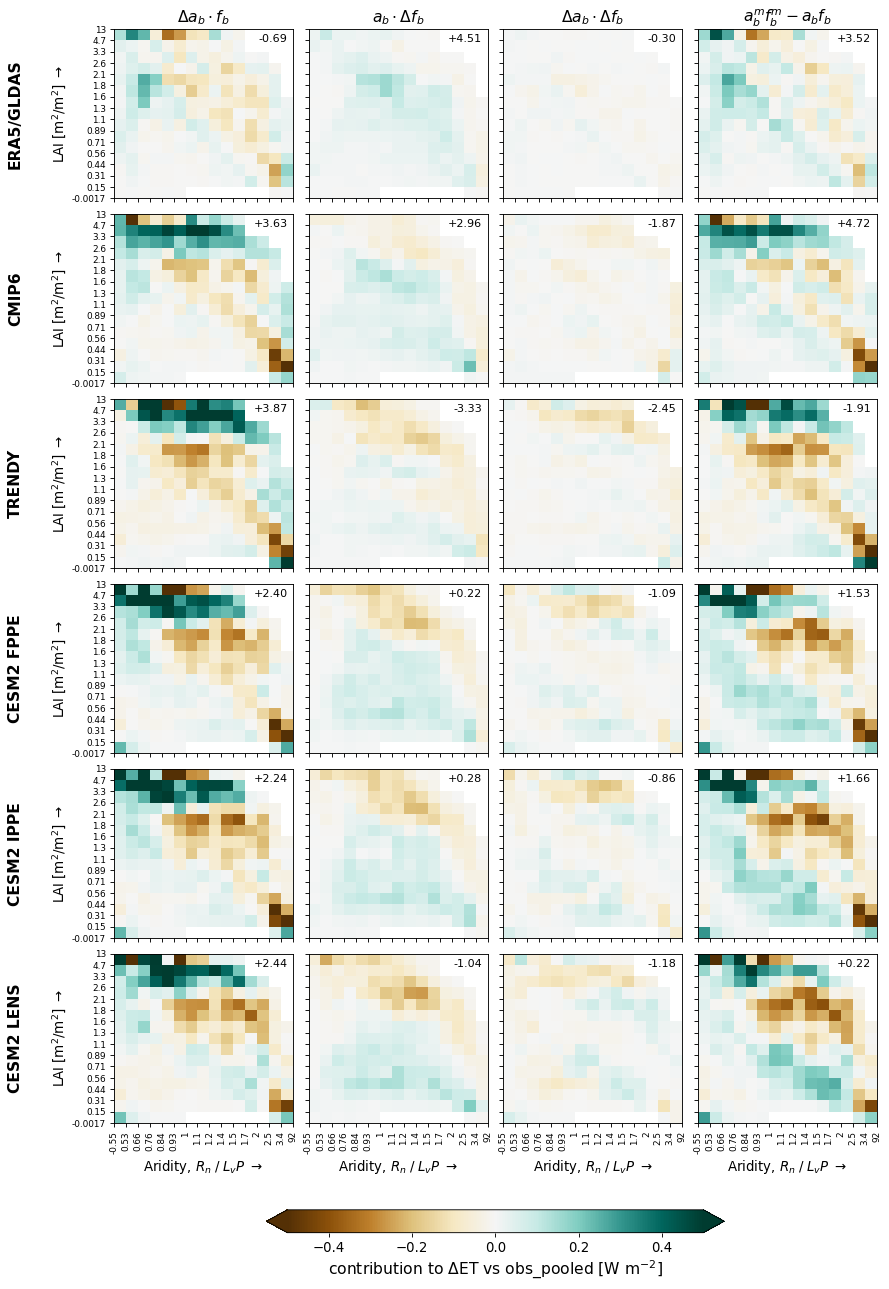

In [20]:
COLS = list(TERMS) + ["TOTAL"]
COL_LABELS = {**TERMS, "TOTAL": TOTAL_LABEL}

fig, axes = plt.subplots(
    nrows=len(DECOMP_FAMILIES),
    ncols=len(COLS),
    figsize=(11, 16),
    layout="constrained",
    dpi=DPI,
)

for r, f in enumerate(DECOMP_FAMILIES):
    for c, t in enumerate(COLS):
        ax = axes[r, c]
        da = pooled[f][t]
        mp = da.plot(
            ax=ax, x="x_bin", y="y_bin",
            cmap=CMAP,
            vmin=-0.5, vmax=0.5,
            # robust=True,
            add_colorbar=False,
            add_labels=False,
        )
        bin_ax(ax, da, xlabels=r == len(DECOMP_FAMILIES) - 1, ylabels=c == 0)
        # Sum over the bins, the domain-mean term
        ax.text(0.97, 0.97, f"{float(da.sum()):+.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=10,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
        if r == 0:
            ax.set_title(COL_LABELS[t], fontsize=14)
    axes[r, 0].annotate(FAMILY_KWARGS["labels"][f], xy=(-0.55, 0.5), xycoords="axes fraction", rotation=90,
                        ha="center", va="center", fontsize=14, fontweight="bold")

cb = fig.colorbar(
    mp,
    ax=axes,
    location="bottom",
    fraction=0.03,
    pad=0.03,
    shrink=0.6,
    extend="both",
)
cb.ax.tick_params(labelsize=12)
cb.set_label("contribution to $\\Delta$ET vs obs_pooled [W m$^{-2}$]", fontsize=14)

### 1.2. Each term on its own color scale

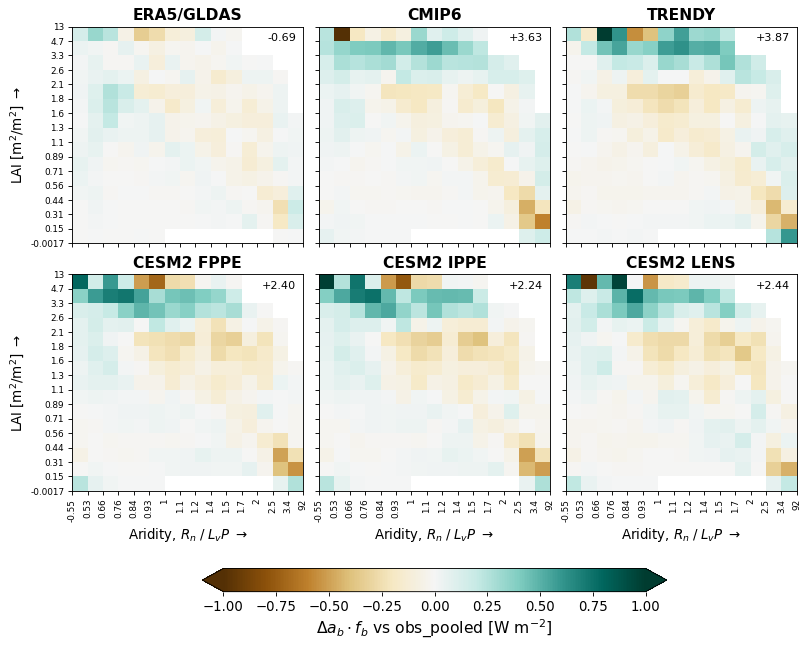

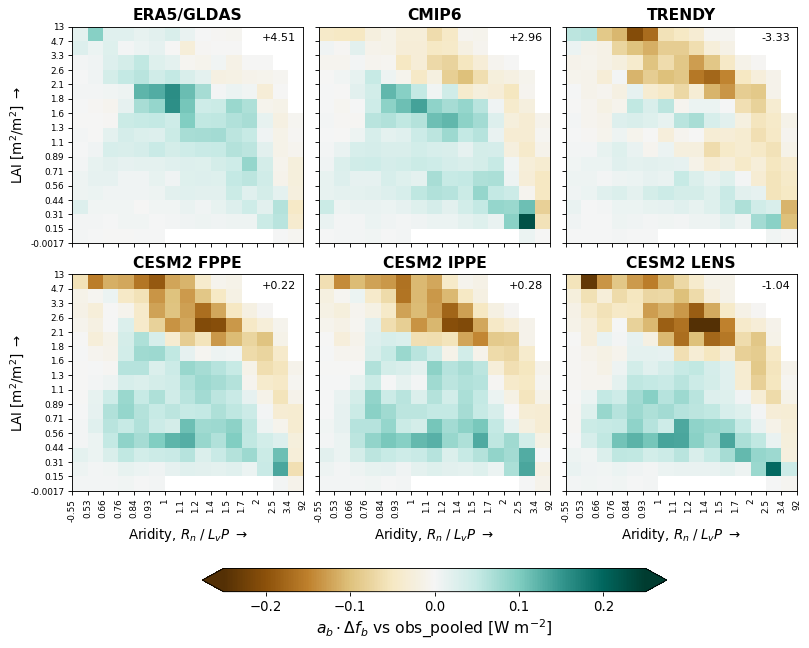

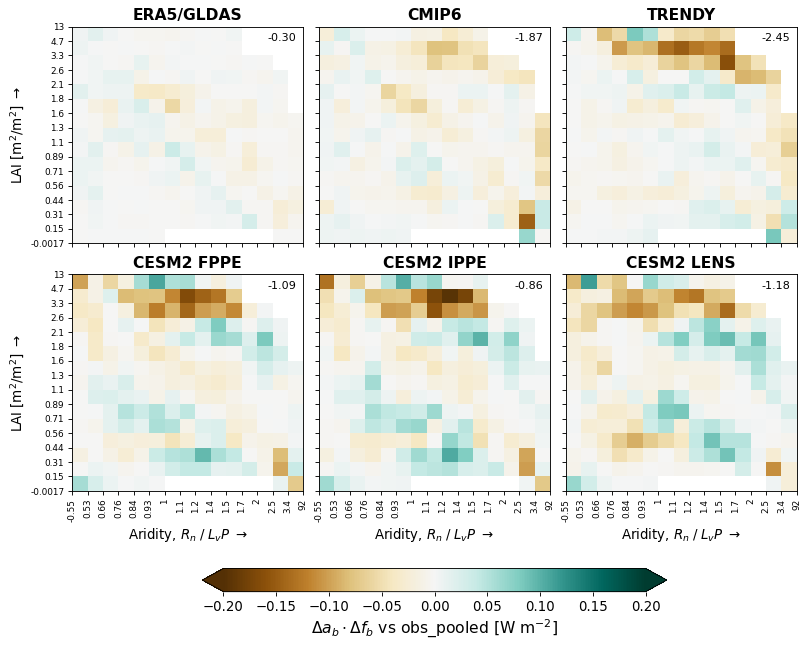

In [9]:
# Color limits of each term, from the range of the pooled families
VMAX_POOLED = {"STATE": 1.0, "FUNCTION": 0.25, "INTERACTION": 0.2}

for t, label in TERMS.items():
    fig, axes = plt.subplots(
        nrows=2,
        ncols=3,
        figsize=(10, 8),
        layout="constrained",
        dpi=DPI,
    )
    axs = axes.ravel()
    ncols = axes.shape[1]

    for i, f in enumerate(DECOMP_FAMILIES):
        da = pooled[f][t]
        mp = da.plot(ax=axs[i], x="x_bin", y="y_bin", cmap=CMAP, vmin=-VMAX_POOLED[t], vmax=VMAX_POOLED[t],
                     add_colorbar=False, add_labels=False)
        bin_ax(axs[i], da, xlabels=i + ncols >= len(DECOMP_FAMILIES), ylabels=i % ncols == 0)
        axs[i].text(0.97, 0.97, f"{float(da.sum()):+.2f}", transform=axs[i].transAxes, ha="right", va="top",
                    fontsize=10, bbox=dict(facecolor="white", edgecolor="none", pad=1))
        axs[i].set_title(FAMILY_KWARGS["labels"][f], fontsize=14, fontweight="bold")

    cb = fig.colorbar(
        mp,
        ax=axs,
        location="bottom",
        fraction=0.05,
        pad=0.05,
        extend="both",
    )
    cb.ax.tick_params(labelsize=12)
    cb.set_label(f"{label} vs obs_pooled [W m$^{{-2}}$]", fontsize=14)
    plt.show()

## 2. Spread across members

### 2.1. Standard deviation of each term across each family's members
Across the members, each against `obs_pooled` (the `<family>_pooled` dataset left out), skipping the members for which the bin is off the common support.

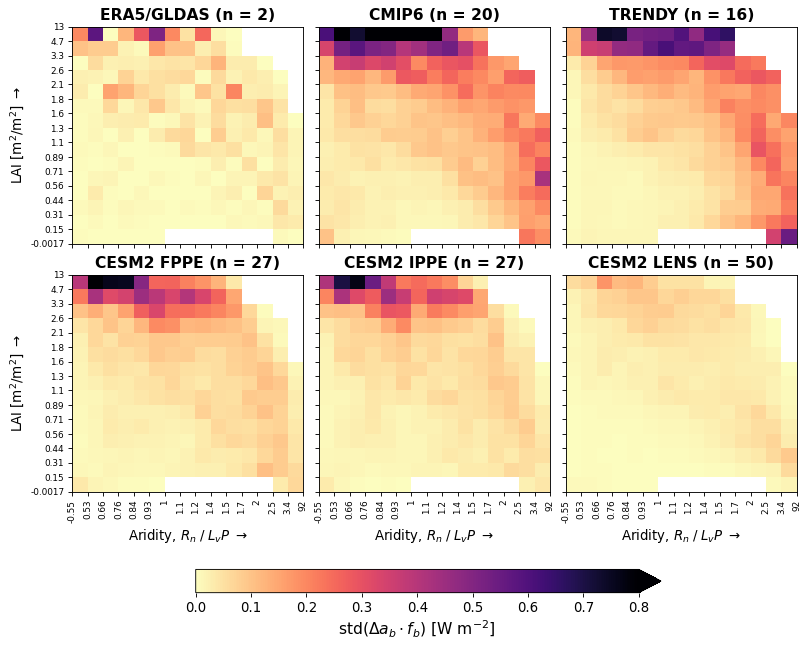

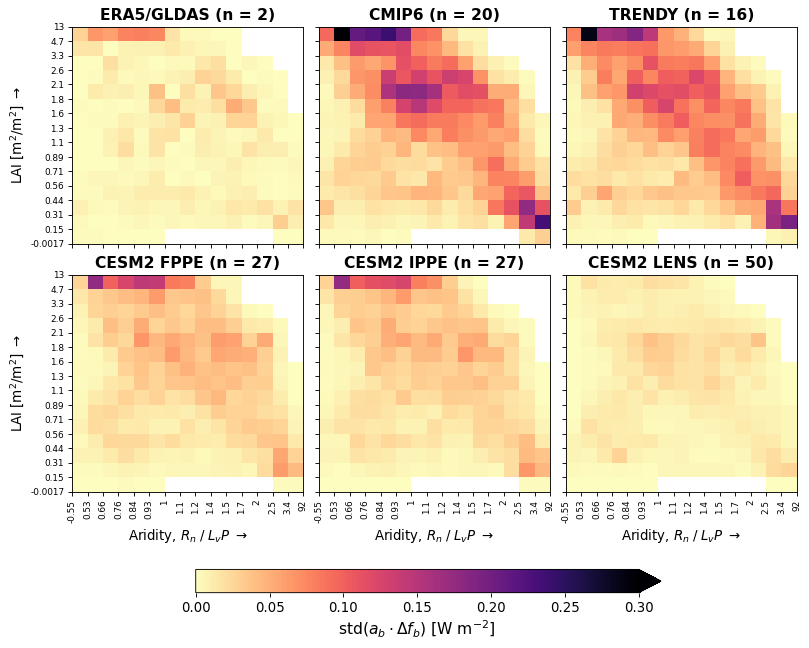

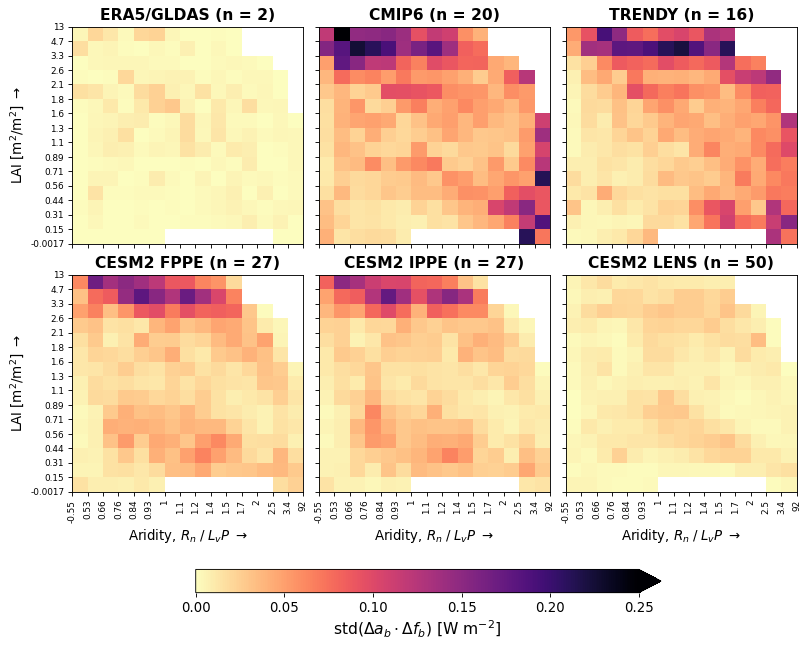

In [10]:
VMAX_STD = {"STATE": 0.8, "FUNCTION": 0.3, "INTERACTION": 0.25}

for t, label in TERMS.items():
    fig, axes = plt.subplots(
        nrows=2,
        ncols=3,
        figsize=(10, 8),
        layout="constrained",
        dpi=DPI,
    )
    axs = axes.ravel()
    ncols = axes.shape[1]

    for i, f in enumerate(DECOMP_FAMILIES):
        # da = variants.group_means(members[f][t], f, "dataset").std("group")
        da = members[f][t].std("dataset")
        mp = da.plot(ax=axs[i], x="x_bin", y="y_bin", cmap="magma_r", vmin=0, vmax=VMAX_STD[t],
                     add_colorbar=False, add_labels=False)
        bin_ax(axs[i], da, xlabels=i + ncols >= len(DECOMP_FAMILIES), ylabels=i % ncols == 0)
        axs[i].set_title(f"{FAMILY_KWARGS['labels'][f]} (n = {members[f].sizes['dataset']})", fontsize=14,
                         fontweight="bold")

    cb = fig.colorbar(
        mp,
        ax=axs,
        location="bottom",
        fraction=0.05,
        pad=0.05,
        extend="max",
    )
    cb.ax.tick_params(labelsize=12)
    cb.set_label(f"std({label}) [W m$^{{-2}}$]", fontsize=14)
    plt.show()

## 3. Distribution of the terms across the bins

### 3.1. Histogram of each term over the bins of each pooled family
The (y_bin, x_bin) bins of each `<family>_pooled` dataset (against `obs_pooled`, as in 1.1) flattened into one vector, without the bins off the common support, and the histogram of each term over that vector: the y-axis is the number of bins. The histogram edges are the same for every family and term, and the legend gives each term's sum over the bins (its value in `decomp_vs_obs`). The skewness (skew) of each term is the Fisher-Pearson coefficient (`scipy.stats.skew`) of its values over the bins, each bin counting once as in the histogram: positive when the bins far from 0 are mostly positive.

(np.float64(0.7665111764011622), np.float64(7984.228003998505))

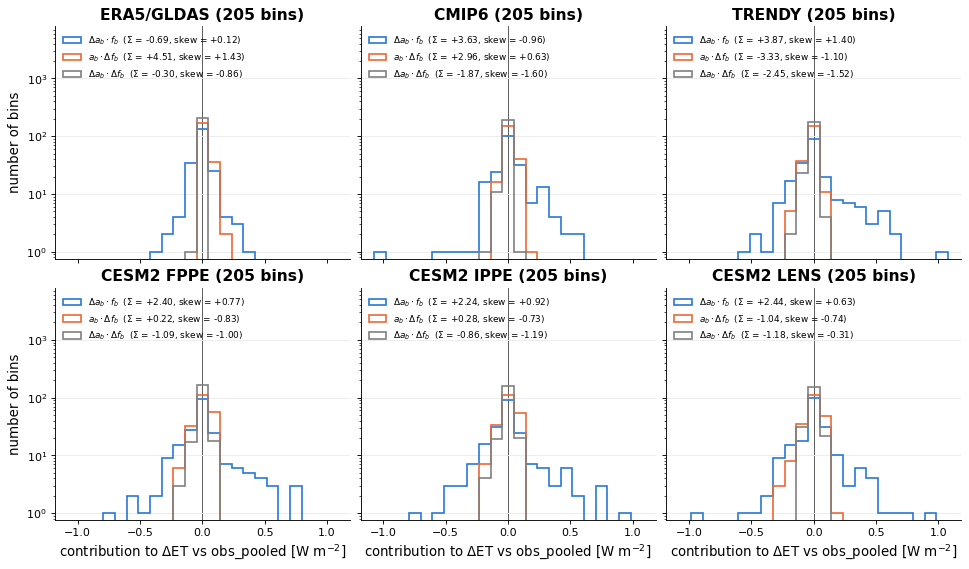

In [11]:
# As TERM_COLORS of final-figures-v1.ipynb S1.3
TERM_COLORS = {"STATE": "#2a78d6", "FUNCTION": "#eb6834", "INTERACTION": "#808080"}


def flatten_bins(da):
    # The (y_bin, x_bin) bins as one vector, without the bins off the common support (NaN)
    v = da.stack(bin=("y_bin", "x_bin")).values
    return v[np.isfinite(v)]


# Histogram edges shared by every family and term: symmetric, one bin centered on 0, covering every value
hist_lim = max(float(abs(pooled[f][t]).max()) for f in DECOMP_FAMILIES for t in TERMS)
HIST_EDGES = np.linspace(-hist_lim, hist_lim, 24)
LOG_Y = True  # True: log y-axis, to see the tails beside the peak at 0

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    sharex=True,
    sharey=True,
    figsize=(12, 7),
    layout="constrained",
    dpi=DPI,
)
axs = axes.ravel()
ncols = axes.shape[1]

for i, f in enumerate(DECOMP_FAMILIES):
    for t, label in TERMS.items():
        v = flatten_bins(pooled[f][t])
        axs[i].hist(v, bins=HIST_EDGES, histtype="step", linewidth=1.5, color=TERM_COLORS[t],
                    label=f"{label}  ($\\Sigma$ = {v.sum():+.2f}, skew = {stats.skew(v):+.2f})")
    if LOG_Y:
        axs[i].set_yscale("log")
    axs[i].axvline(0, color="0.3", linewidth=0.8, zorder=0)
    axs[i].set_title(f"{FAMILY_KWARGS['labels'][f]} ({v.size} bins)", fontsize=14, fontweight="bold")
    axs[i].legend(loc="upper left", fontsize=8, frameon=False)
    axs[i].grid(axis="y", color="0.92", zorder=0)
    axs[i].spines[["top", "right"]].set_visible(False)
    axs[i].tick_params(labelsize=10)
    if i % ncols == 0:
        axs[i].set_ylabel("number of bins", fontsize=12)
    if i + ncols >= len(DECOMP_FAMILIES):
        axs[i].set_xlabel("contribution to $\\Delta$ET vs obs_pooled [W m$^{-2}$]", fontsize=12)

# Room above the histograms for the legends (shared y-axis)
ymin, ymax = axs[0].get_ylim()
axs[0].set_ylim(ymin, ymax * (30 if LOG_Y else 1.6))

### 3.2. Histogram of each term over the bins of each member
As 3.1, with one histogram per member (thin lines) and the `<family>_pooled` dataset of 3.1 (black), one figure per term. Members are more extreme than their pooled family, so the histogram edges cover every member, with one set of edges per term (shared by the families). The legend gives the skewness of the pooled dataset and the median of the members' skewness (each member's skewness over its own bins, as in 3.1). `LOG_Y` is that of 3.1. Needs the 3.1 cell to be run first.

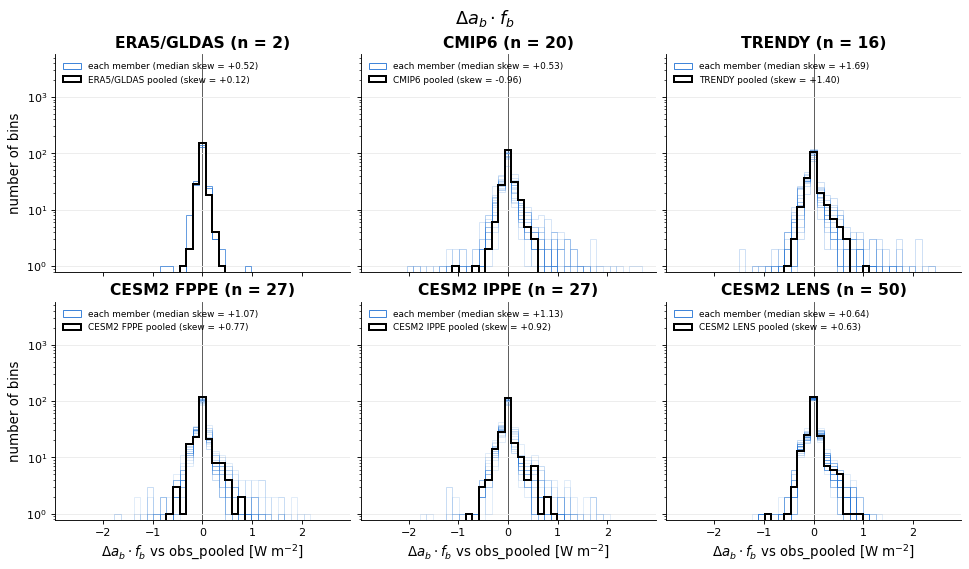

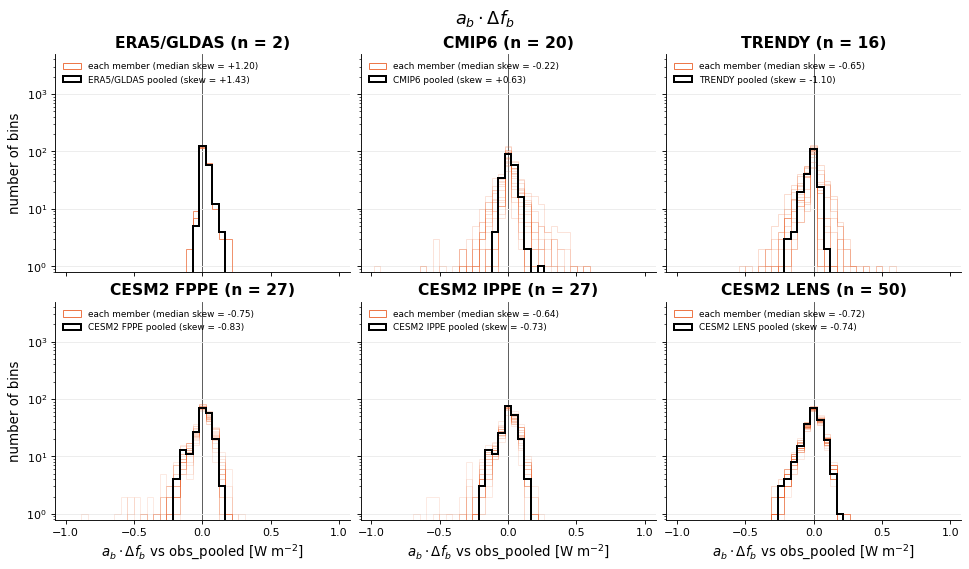

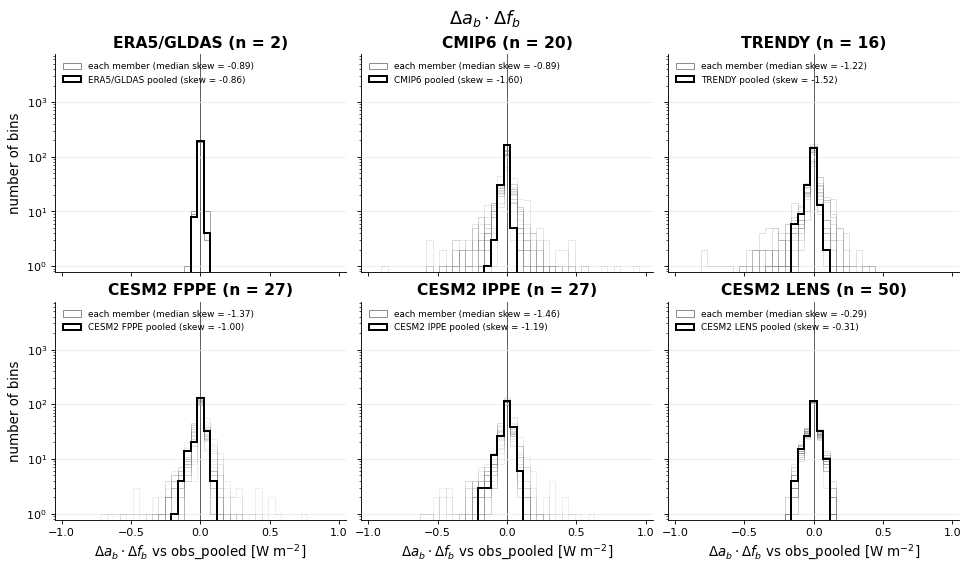

In [12]:
for t, label in TERMS.items():
    # Histogram edges of this term: symmetric, one bin centered on 0, covering every member of every family
    lim = max(float(abs(members[f][t]).max()) for f in DECOMP_FAMILIES)
    edges = np.linspace(-lim, lim, 42)

    fig, axes = plt.subplots(
        nrows=2,
        ncols=3,
        sharex=True,
        sharey=True,
        figsize=(12, 7),
        layout="constrained",
        dpi=DPI,
    )
    axs = axes.ravel()
    ncols = axes.shape[1]

    for i, f in enumerate(DECOMP_FAMILIES):
        n = members[f].sizes["dataset"]
        # Skewness of each member over its own bins, and of the pooled dataset
        member_skew = [stats.skew(flatten_bins(members[f][t].isel(dataset=k))) for k in range(n)]
        pooled_skew = stats.skew(flatten_bins(pooled[f][t]))
        # Each member, thinner and more transparent in large families
        for k in range(n):
            axs[i].hist(flatten_bins(members[f][t].isel(dataset=k)), bins=edges, histtype="step",
                        linewidth=0.8, alpha=max(0.15, min(0.8, 4 / n)), color=TERM_COLORS[t],
                        label=f"each member (median skew = {np.median(member_skew):+.2f})" if k == 0 else None)
        axs[i].hist(flatten_bins(pooled[f][t]), bins=edges, histtype="step", linewidth=1.8, color="k",
                    label=f"{FAMILY_KWARGS['labels'][f]} pooled (skew = {pooled_skew:+.2f})")
        if LOG_Y:
            axs[i].set_yscale("log")
        axs[i].axvline(0, color="0.3", linewidth=0.8, zorder=0)
        axs[i].set_title(f"{FAMILY_KWARGS['labels'][f]} (n = {n})", fontsize=14, fontweight="bold")
        leg = axs[i].legend(loc="upper left", fontsize=8, frameon=False)
        for h in leg.legend_handles:  # opaque in the legend, whatever the members' alpha
            h.set_alpha(1)
        axs[i].grid(axis="y", color="0.92", zorder=0)
        axs[i].spines[["top", "right"]].set_visible(False)
        axs[i].tick_params(labelsize=10)
        if i % ncols == 0:
            axs[i].set_ylabel("number of bins", fontsize=12)
        if i + ncols >= len(DECOMP_FAMILIES):
            axs[i].set_xlabel(f"{label} vs obs_pooled [W m$^{{-2}}$]", fontsize=12)
    # Room above the histograms for the legends (shared y-axis)
    ymin, ymax = axs[0].get_ylim()
    axs[0].set_ylim(ymin, ymax * (30 if LOG_Y else 1.6))
    fig.suptitle(label, fontsize=16)
    plt.show()

## S1. Panel plots for all models/members for each data family

### S1.1. $\Delta a_b \cdot f_b$
Each member against `obs_pooled` (`STATE` of `decompose_binned`).

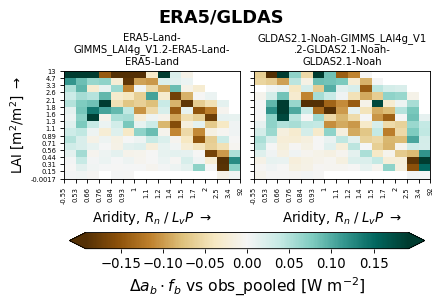

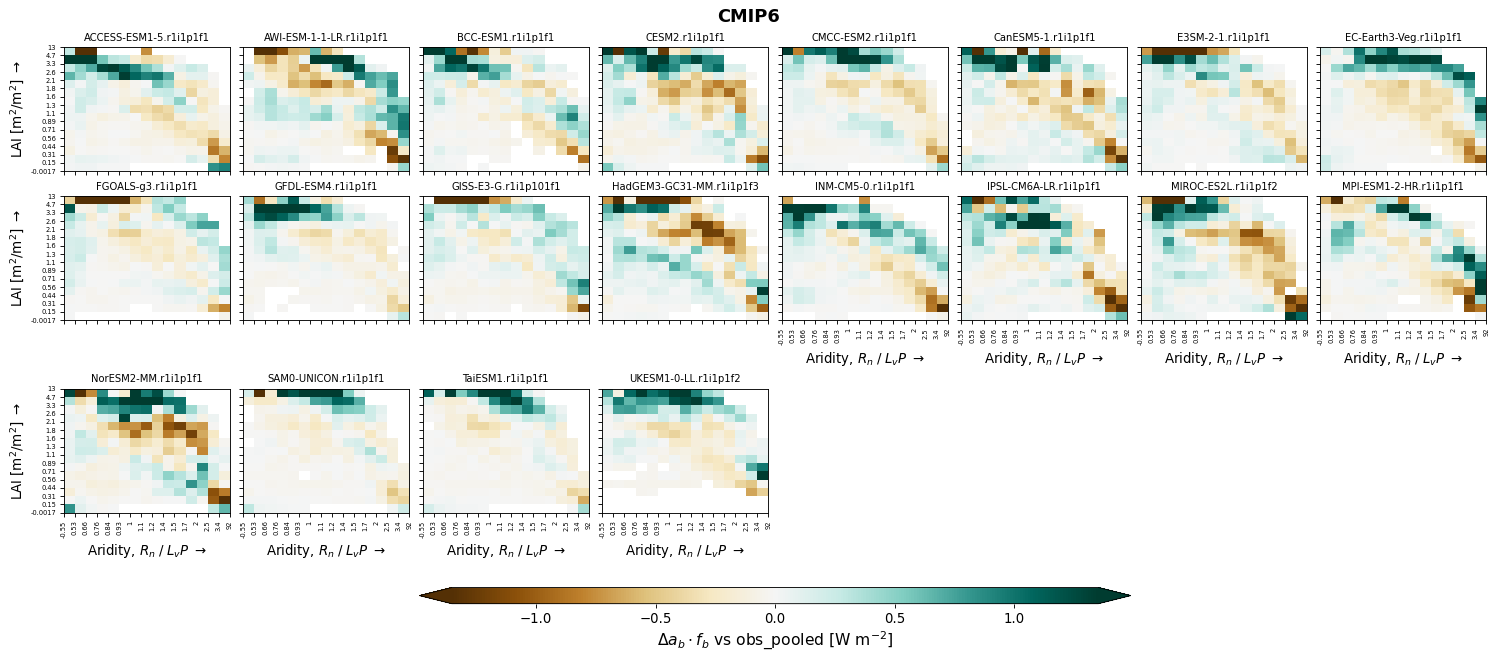

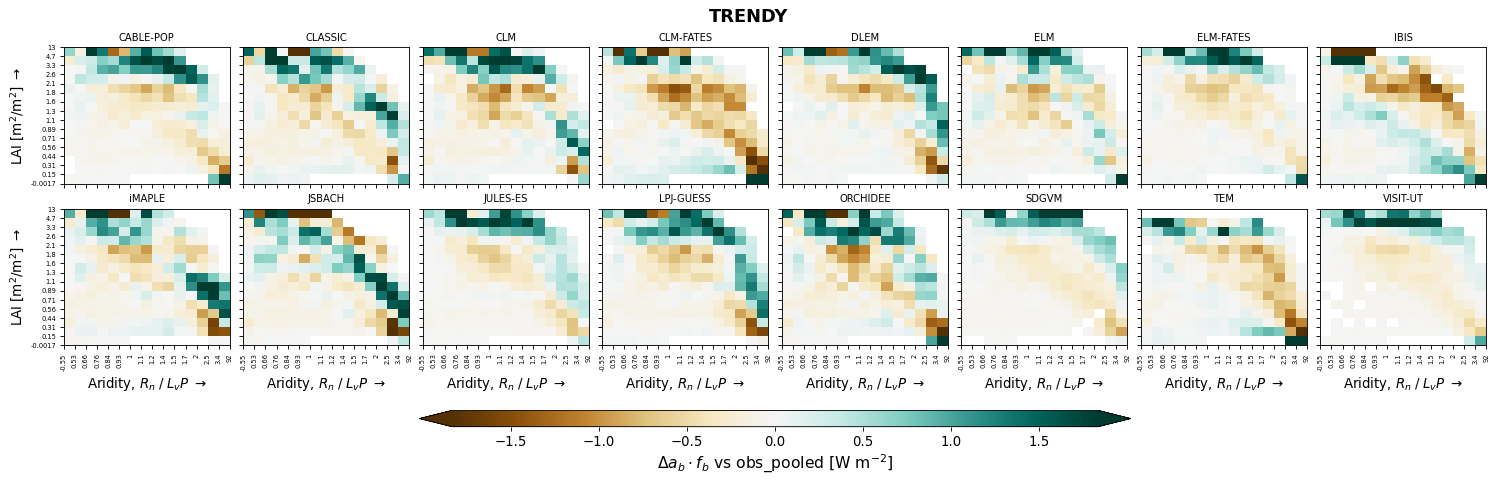

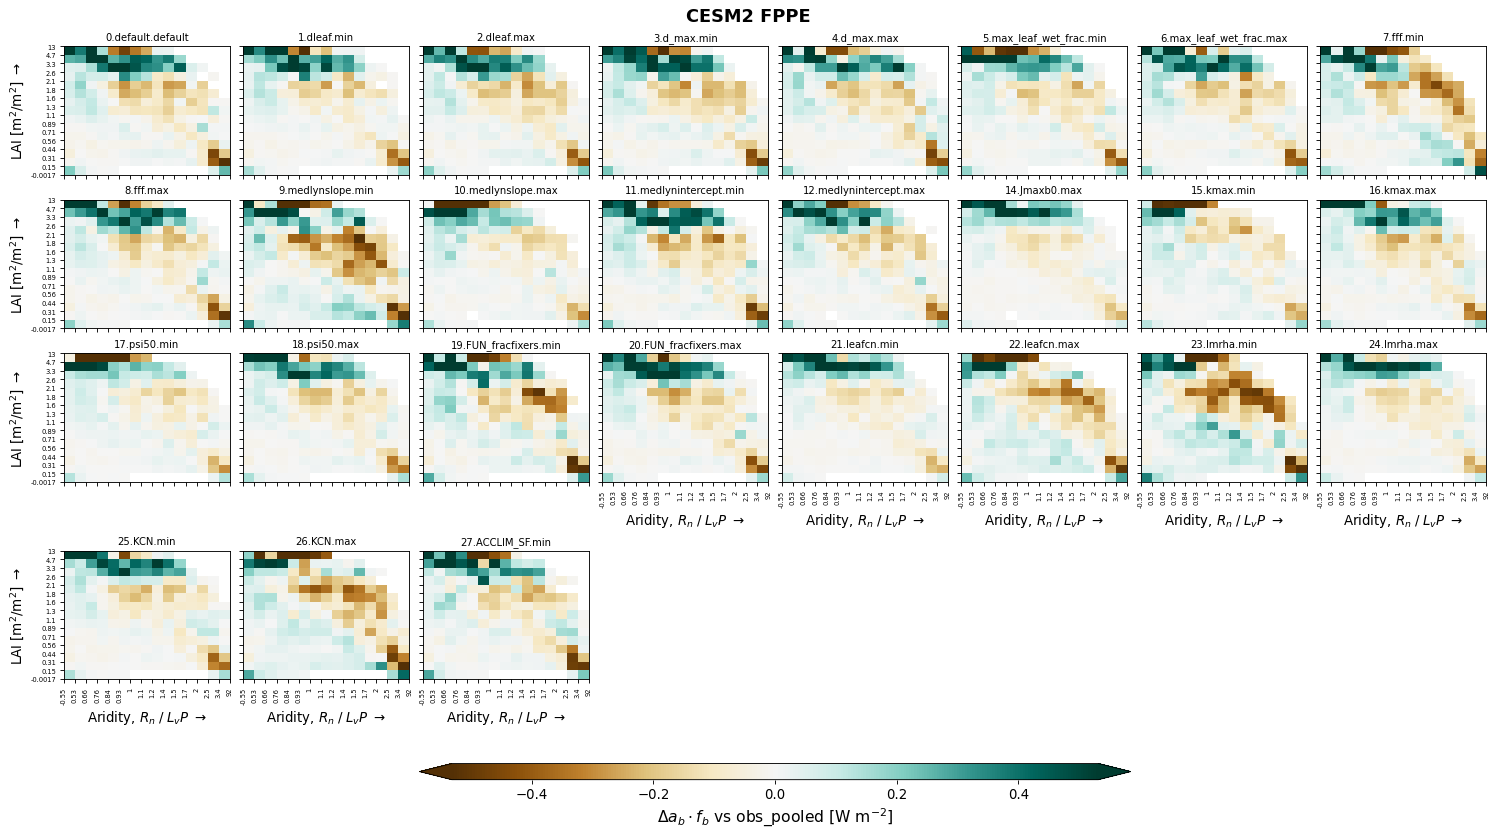

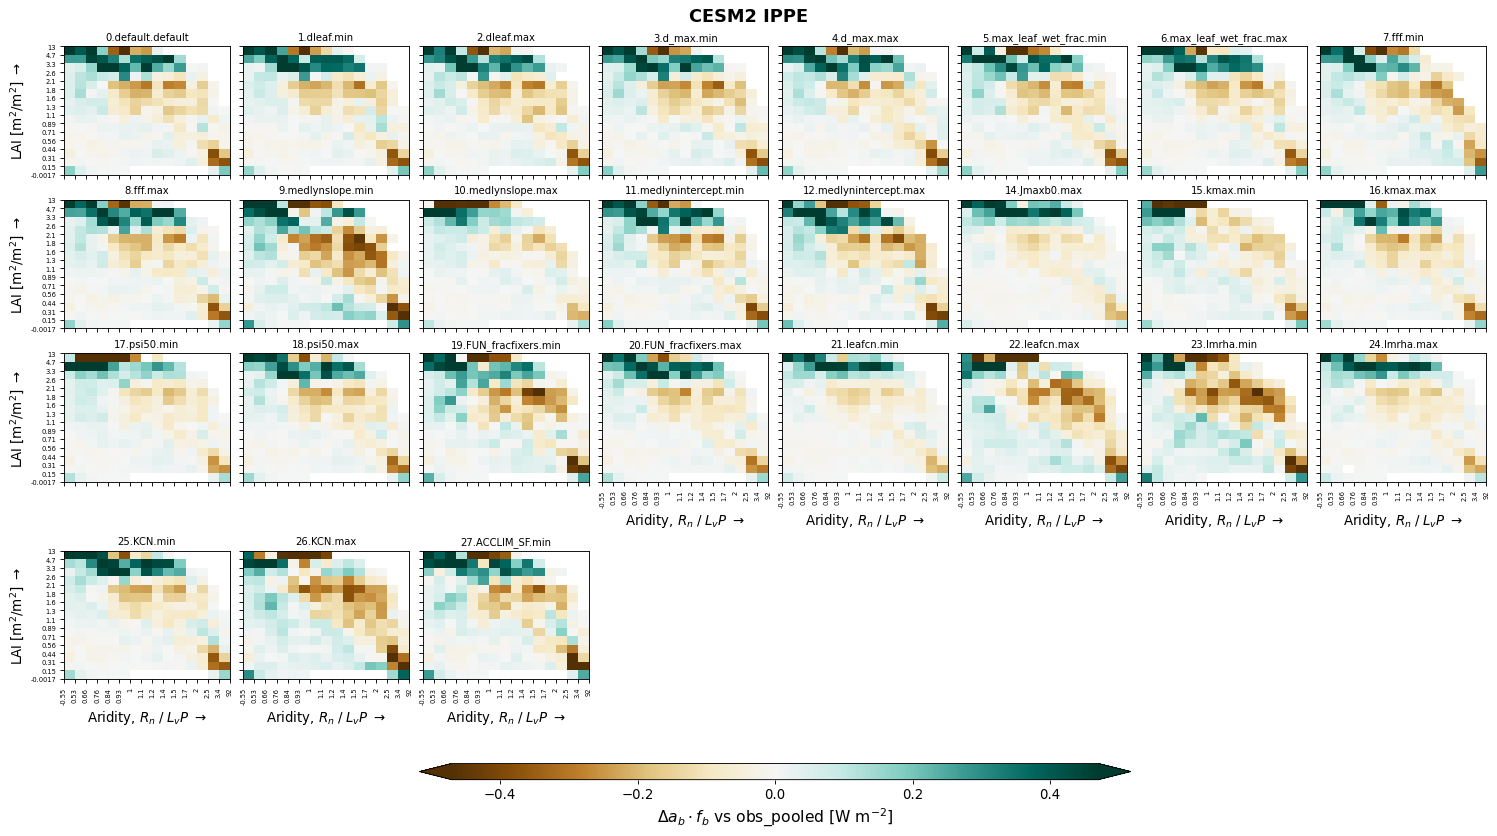

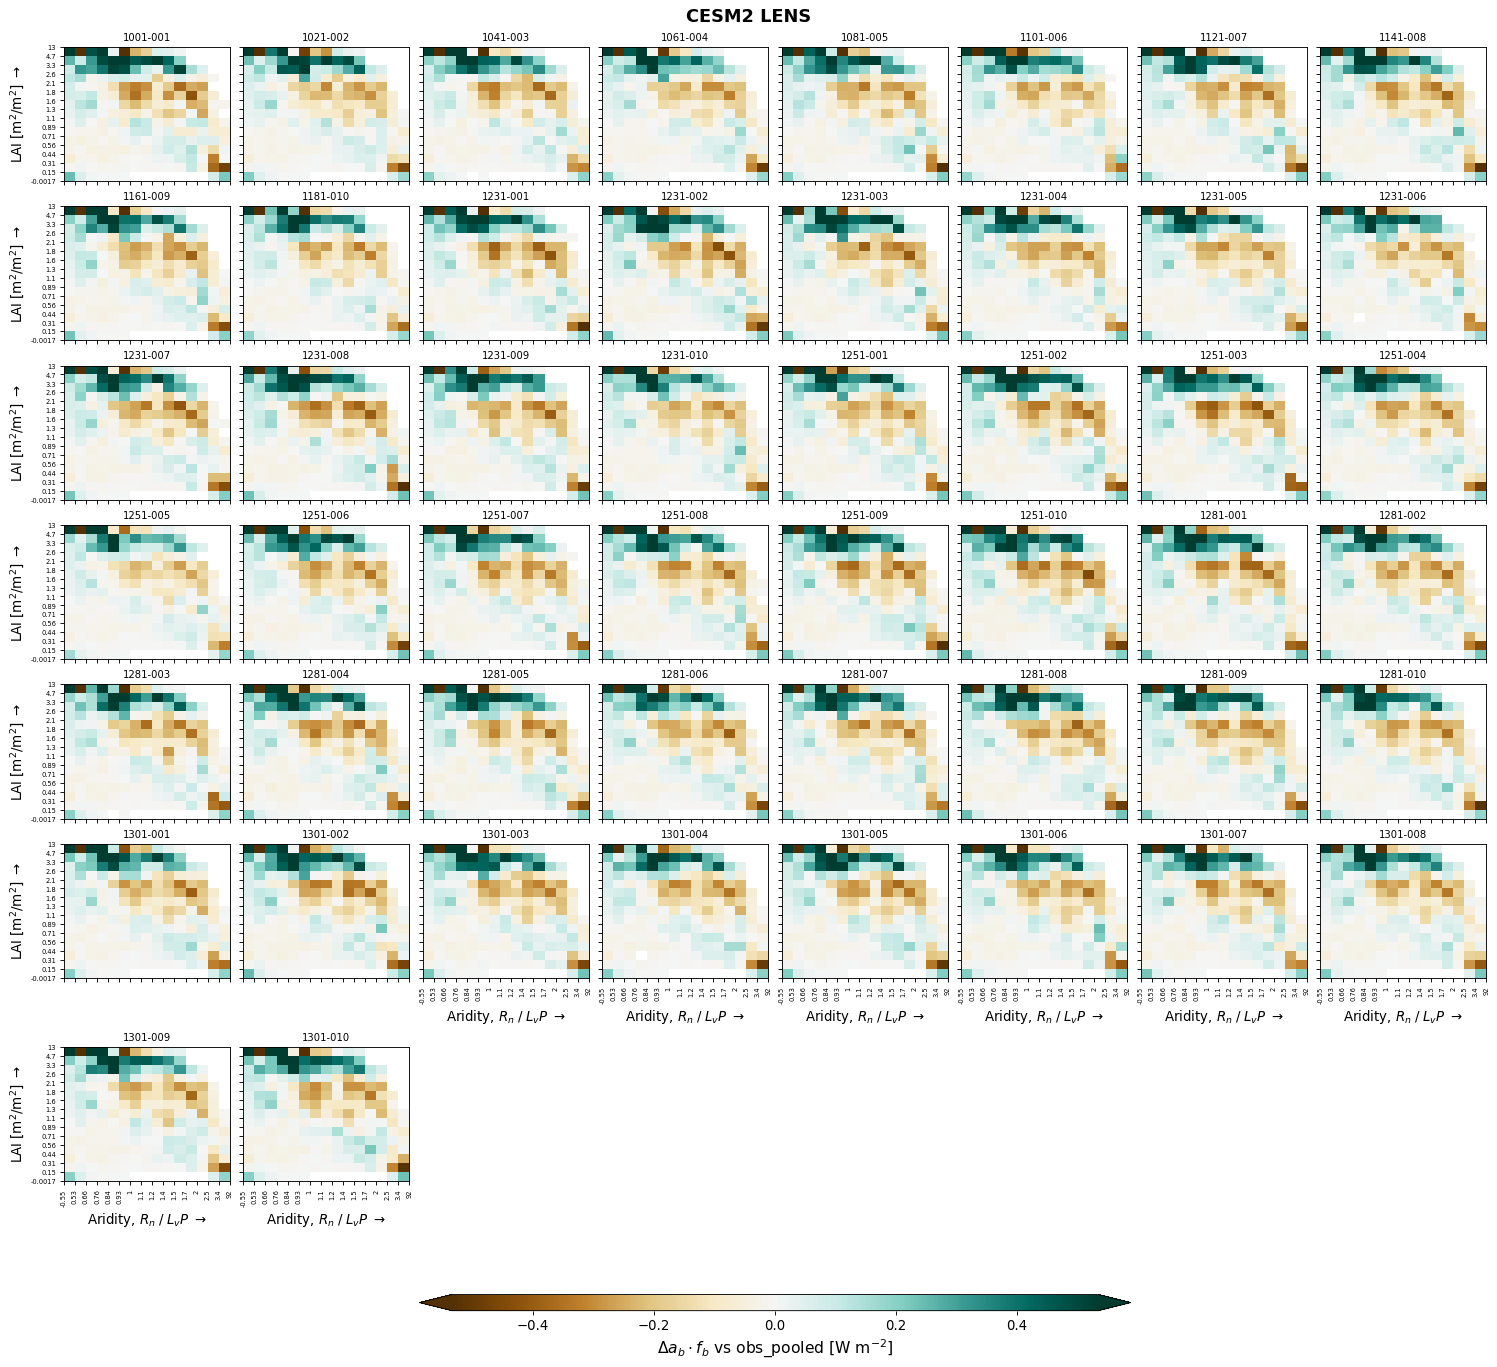

In [13]:
for f in DECOMP_FAMILIES:
    member_panels(members[f]["STATE"], f, TERMS["STATE"] + " vs obs_pooled [W m$^{-2}$]",
                  cmap=CMAP,
                #   vmin=-1.5, vmax=1.5,
                  robust=True,
                  )
    plt.show()

### S1.2. $a_b \cdot \Delta f_b$
Each member against `obs_pooled` (`FUNCTION` of `decompose_binned`). The obs sources are included: their $\Delta a_b = 0$, so this is their only nonzero term.

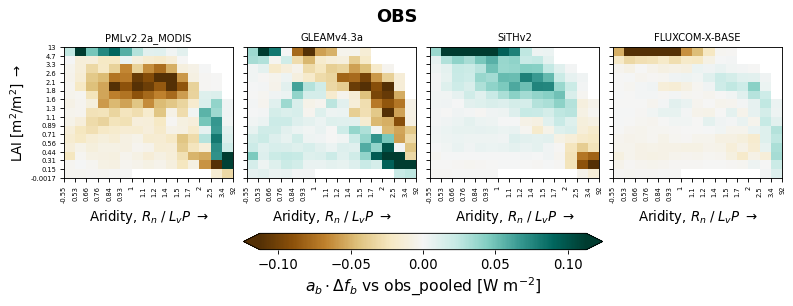

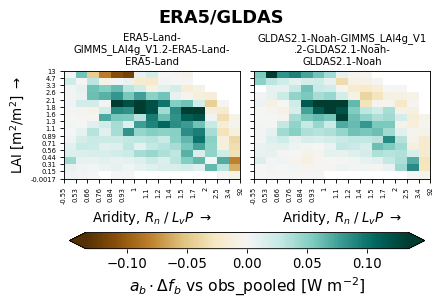

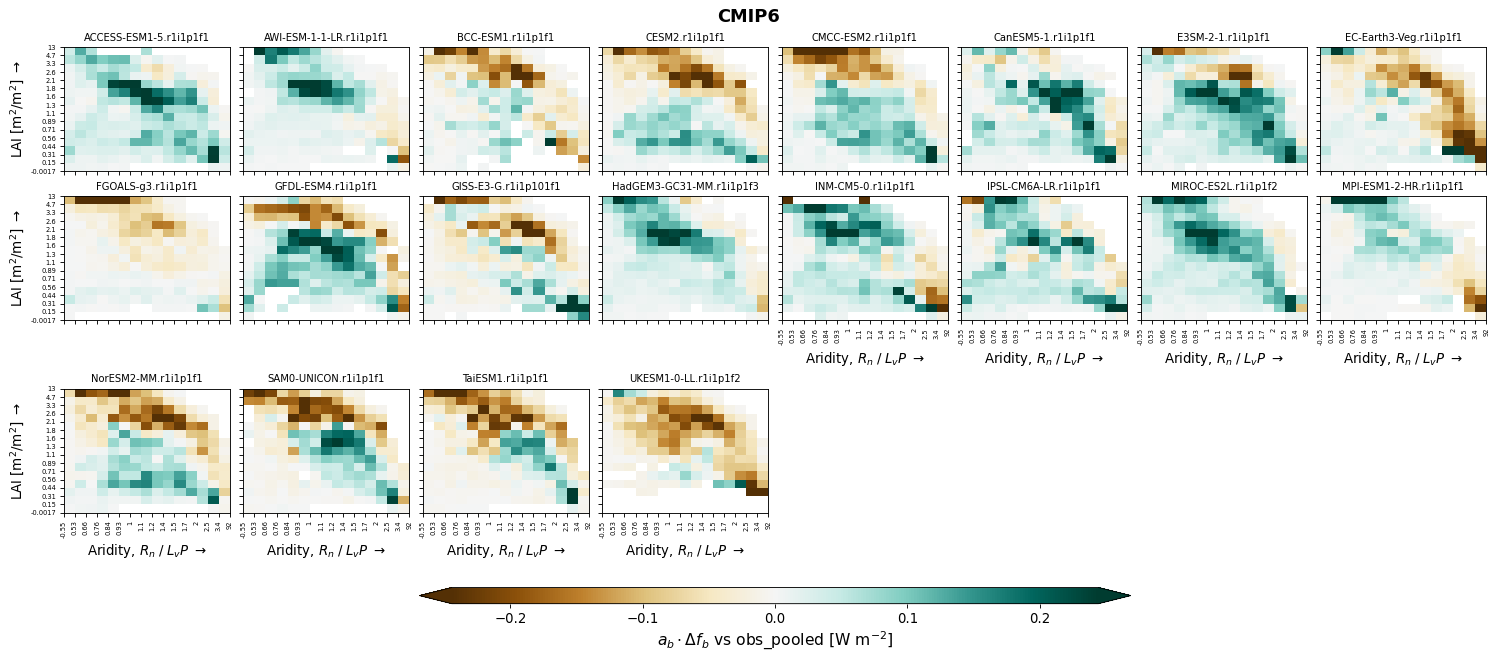

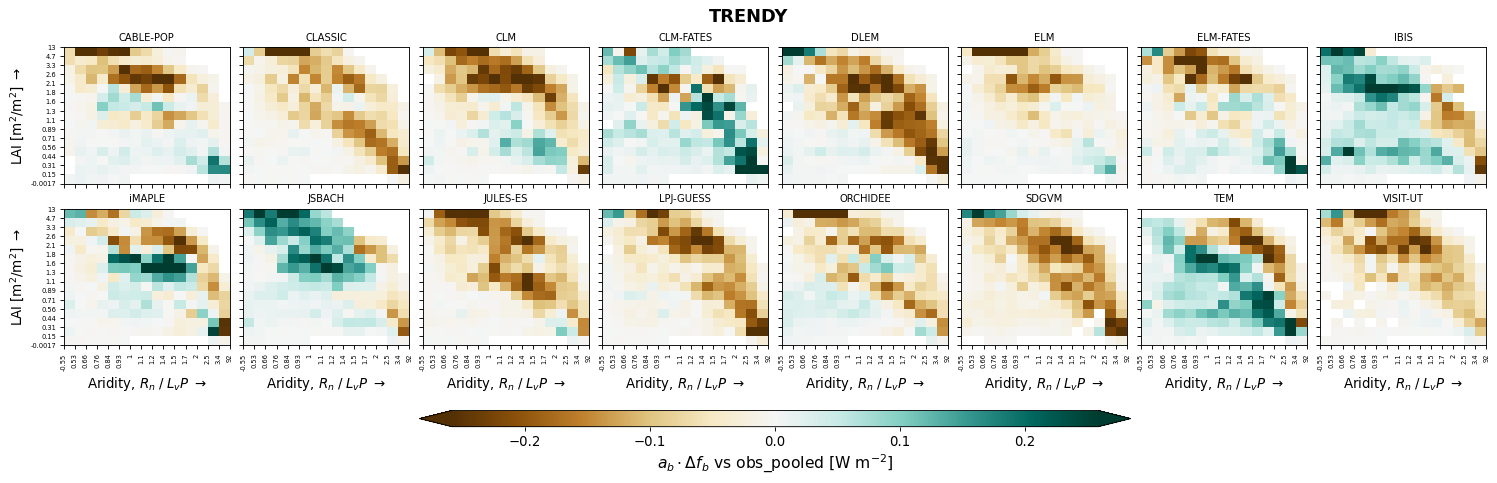

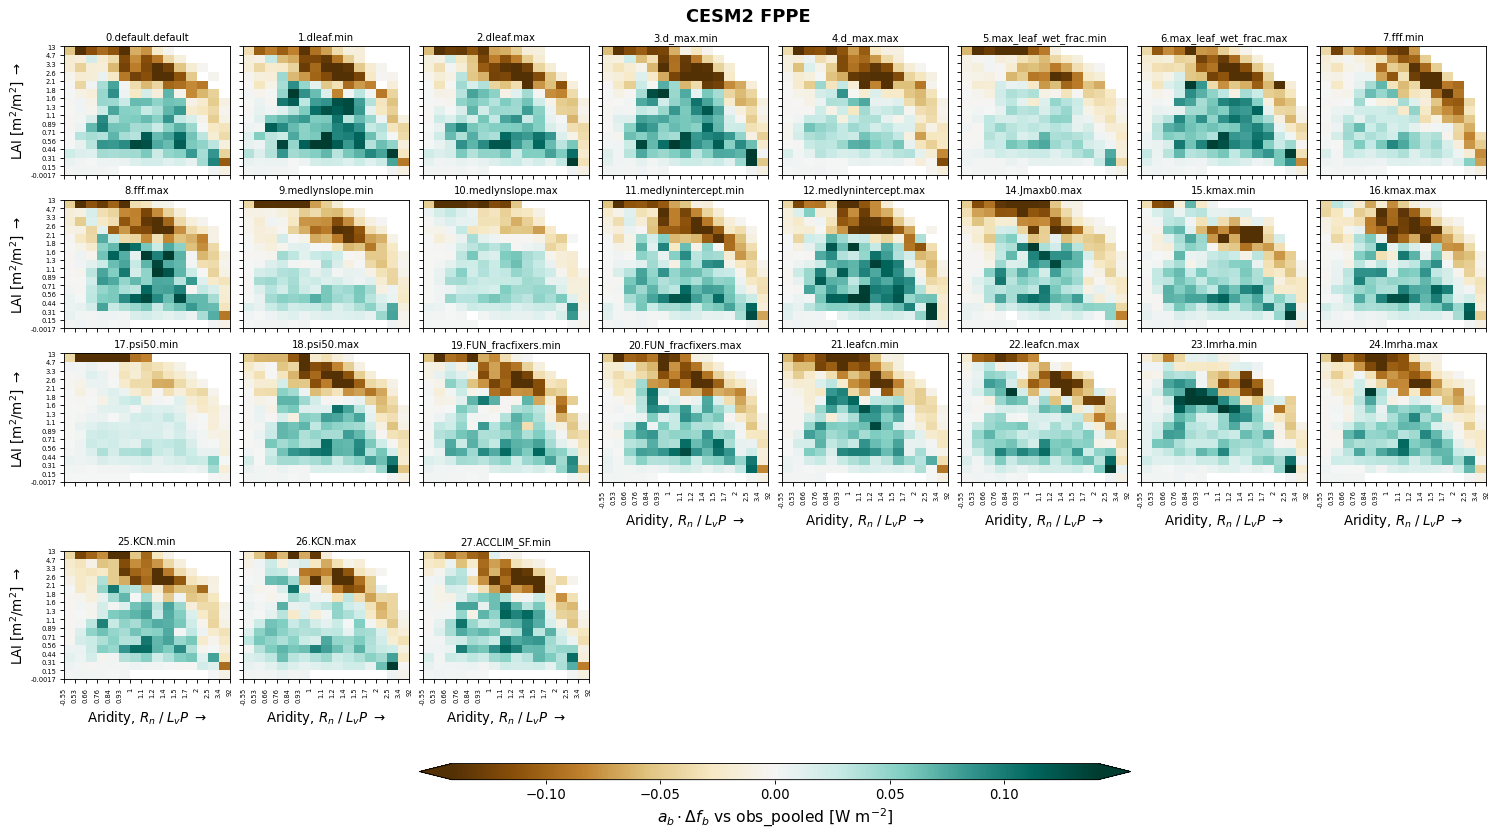

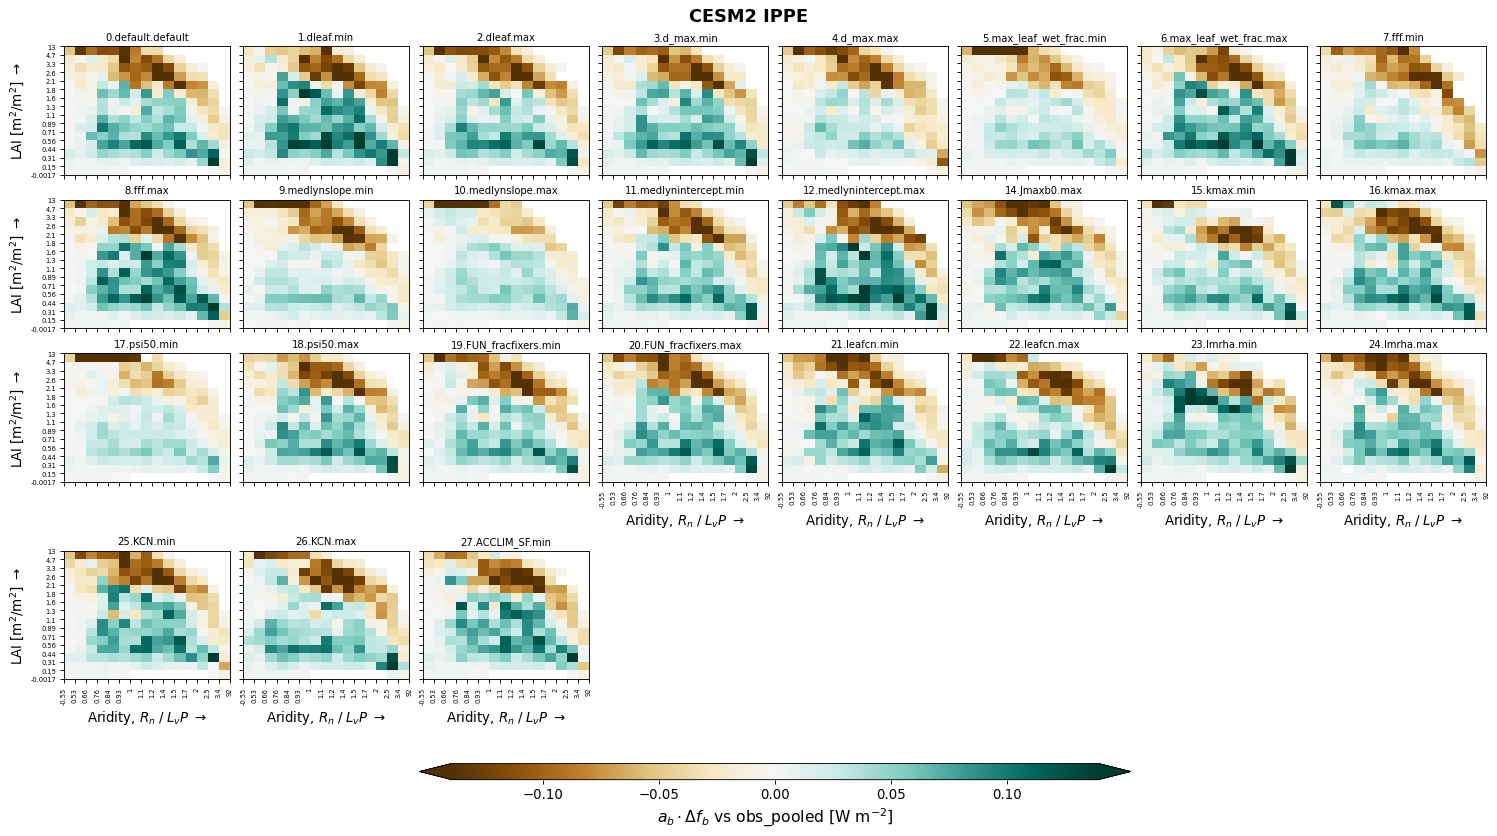

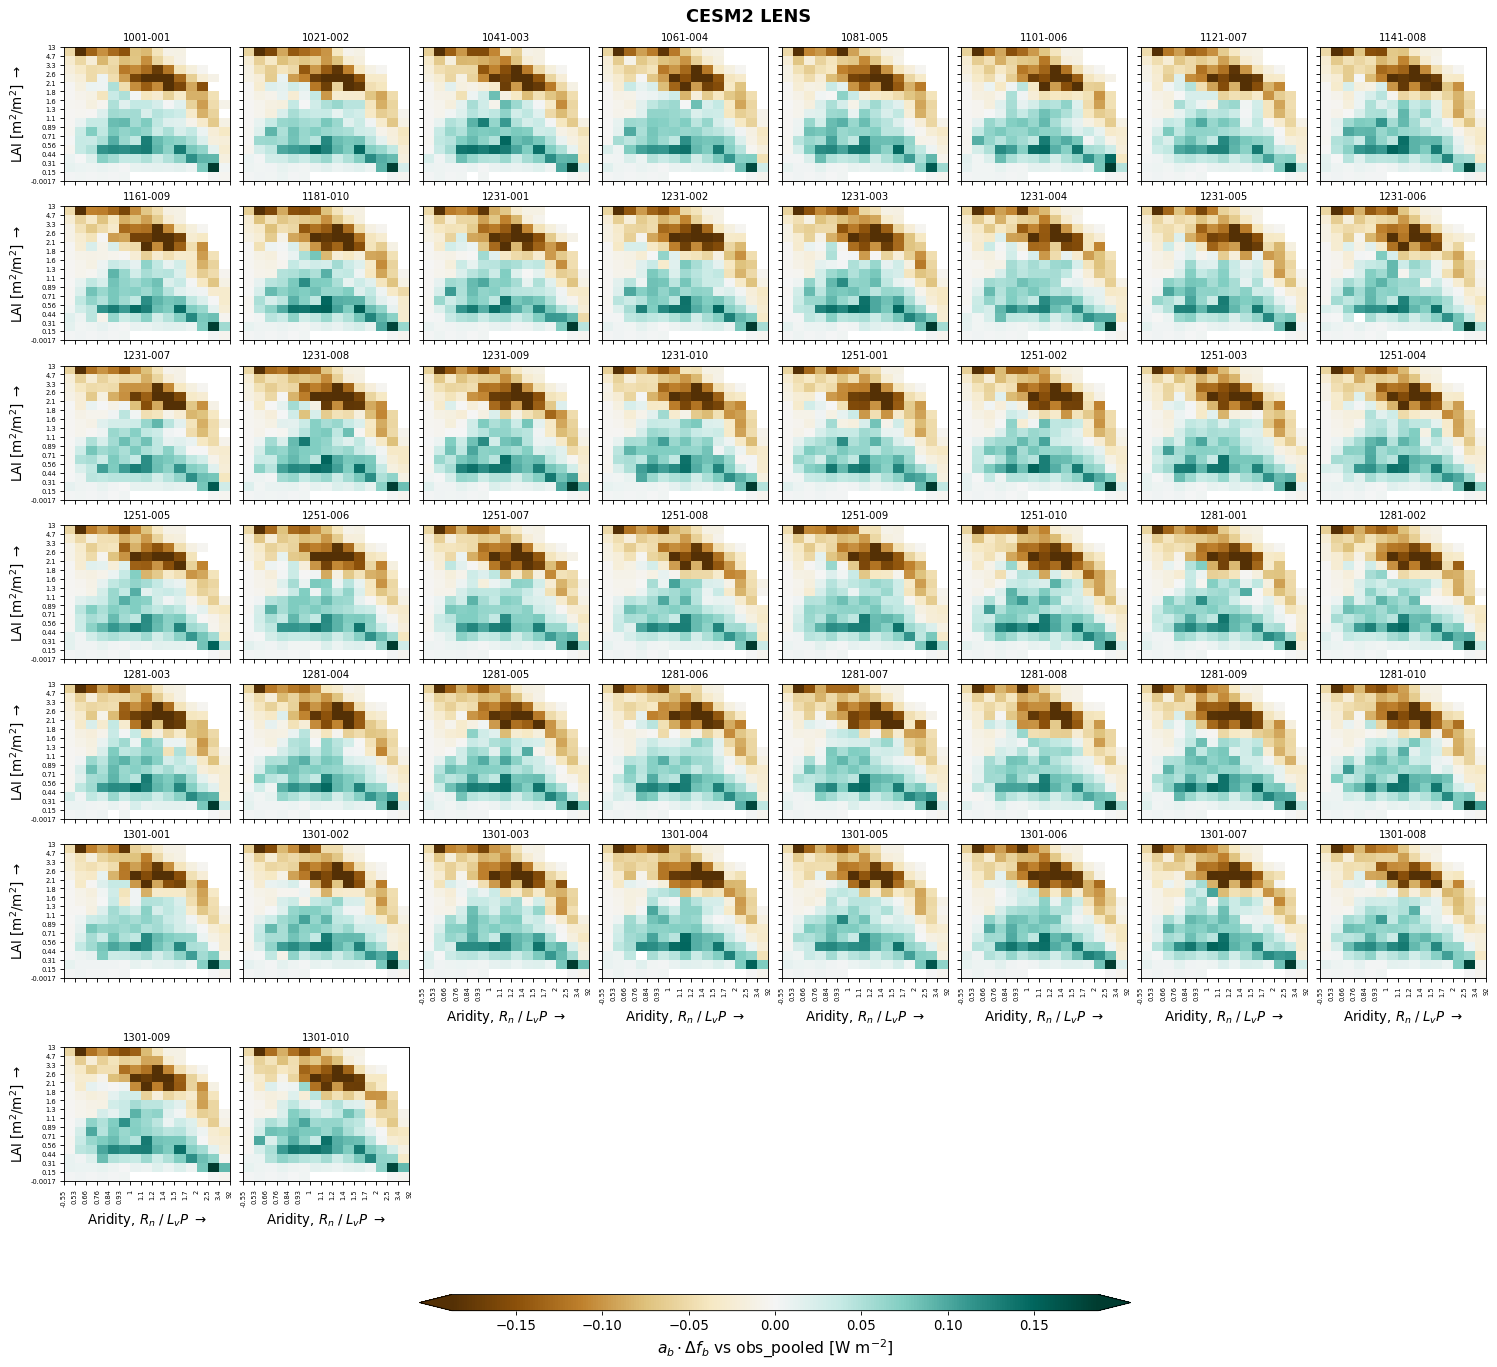

In [17]:
for f in FAMILIES:
    member_panels(members[f]["FUNCTION"], f, TERMS["FUNCTION"] + " vs obs_pooled [W m$^{-2}$]",
                  cmap=CMAP,
                #   vmin=-0.5, vmax=0.5,
                  robust=True,
                )
    plt.show()

### S1.3. $\Delta a_b \cdot \Delta f_b$
Each member against `obs_pooled` (`INTERACTION` of `decompose_binned`).

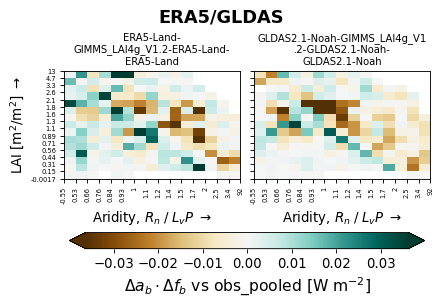

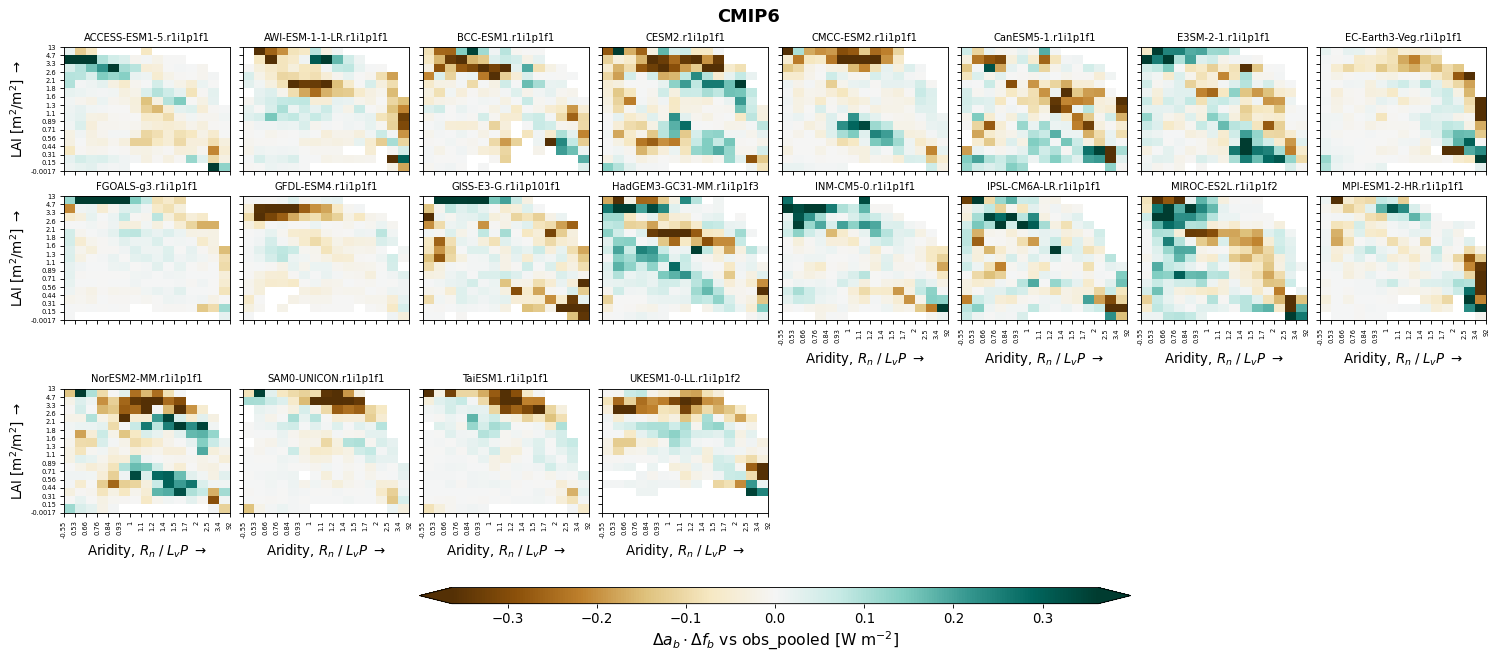

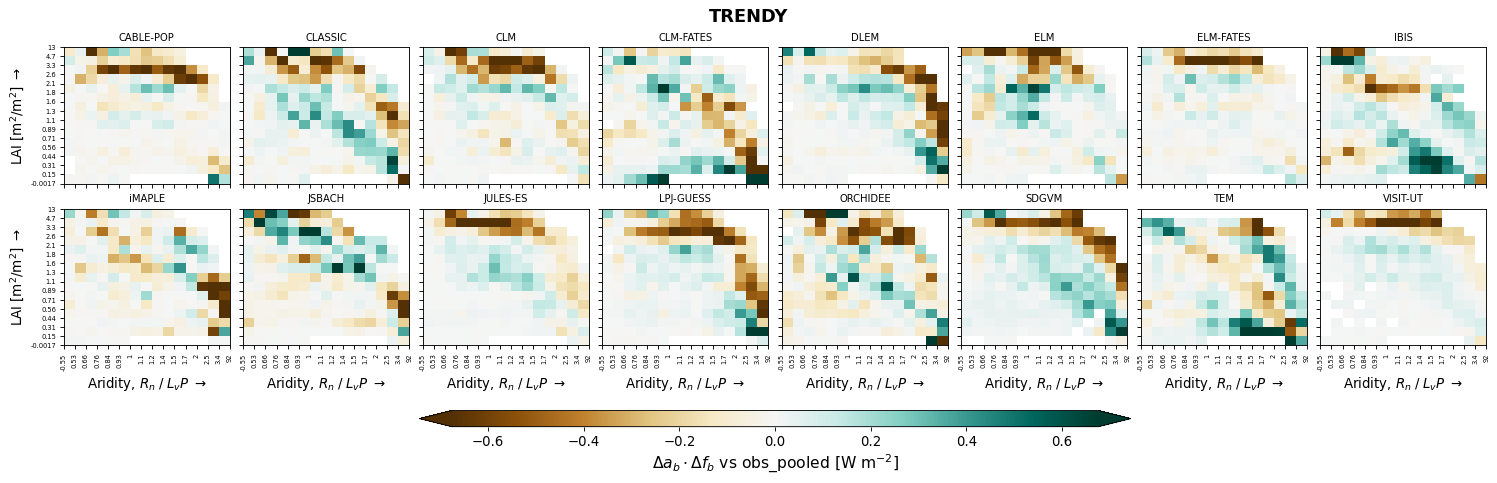

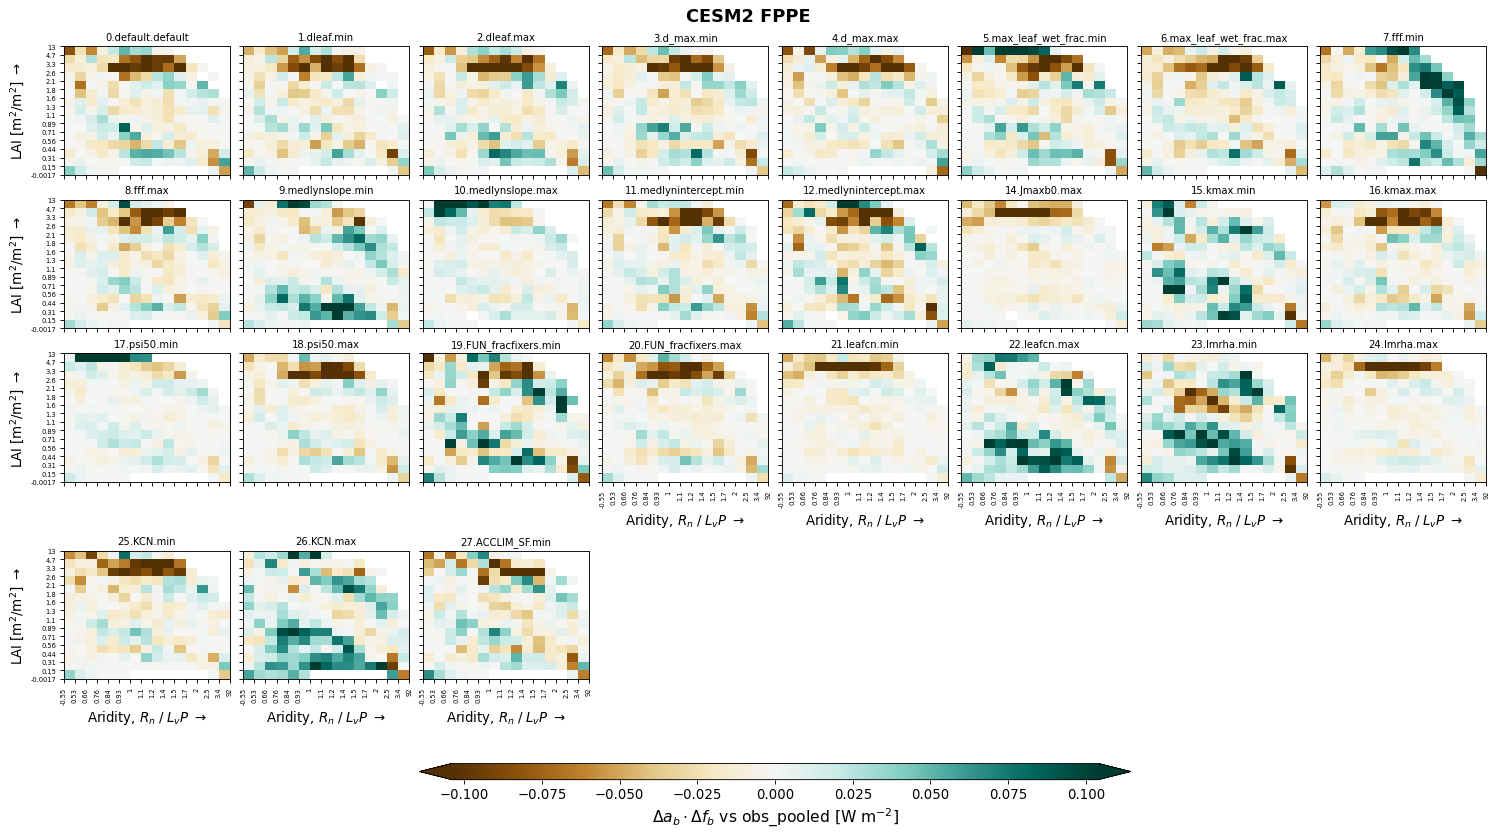

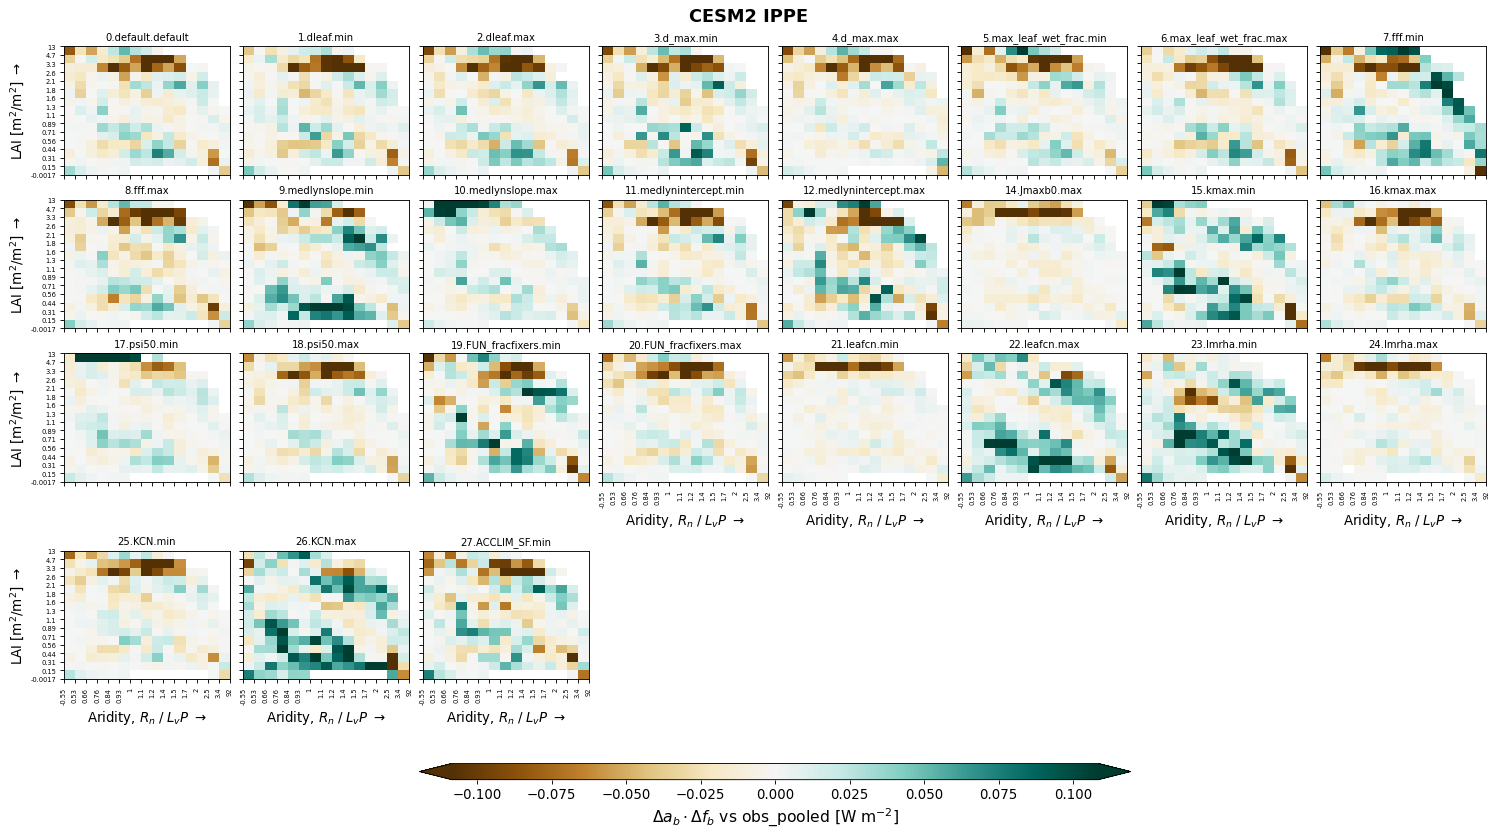

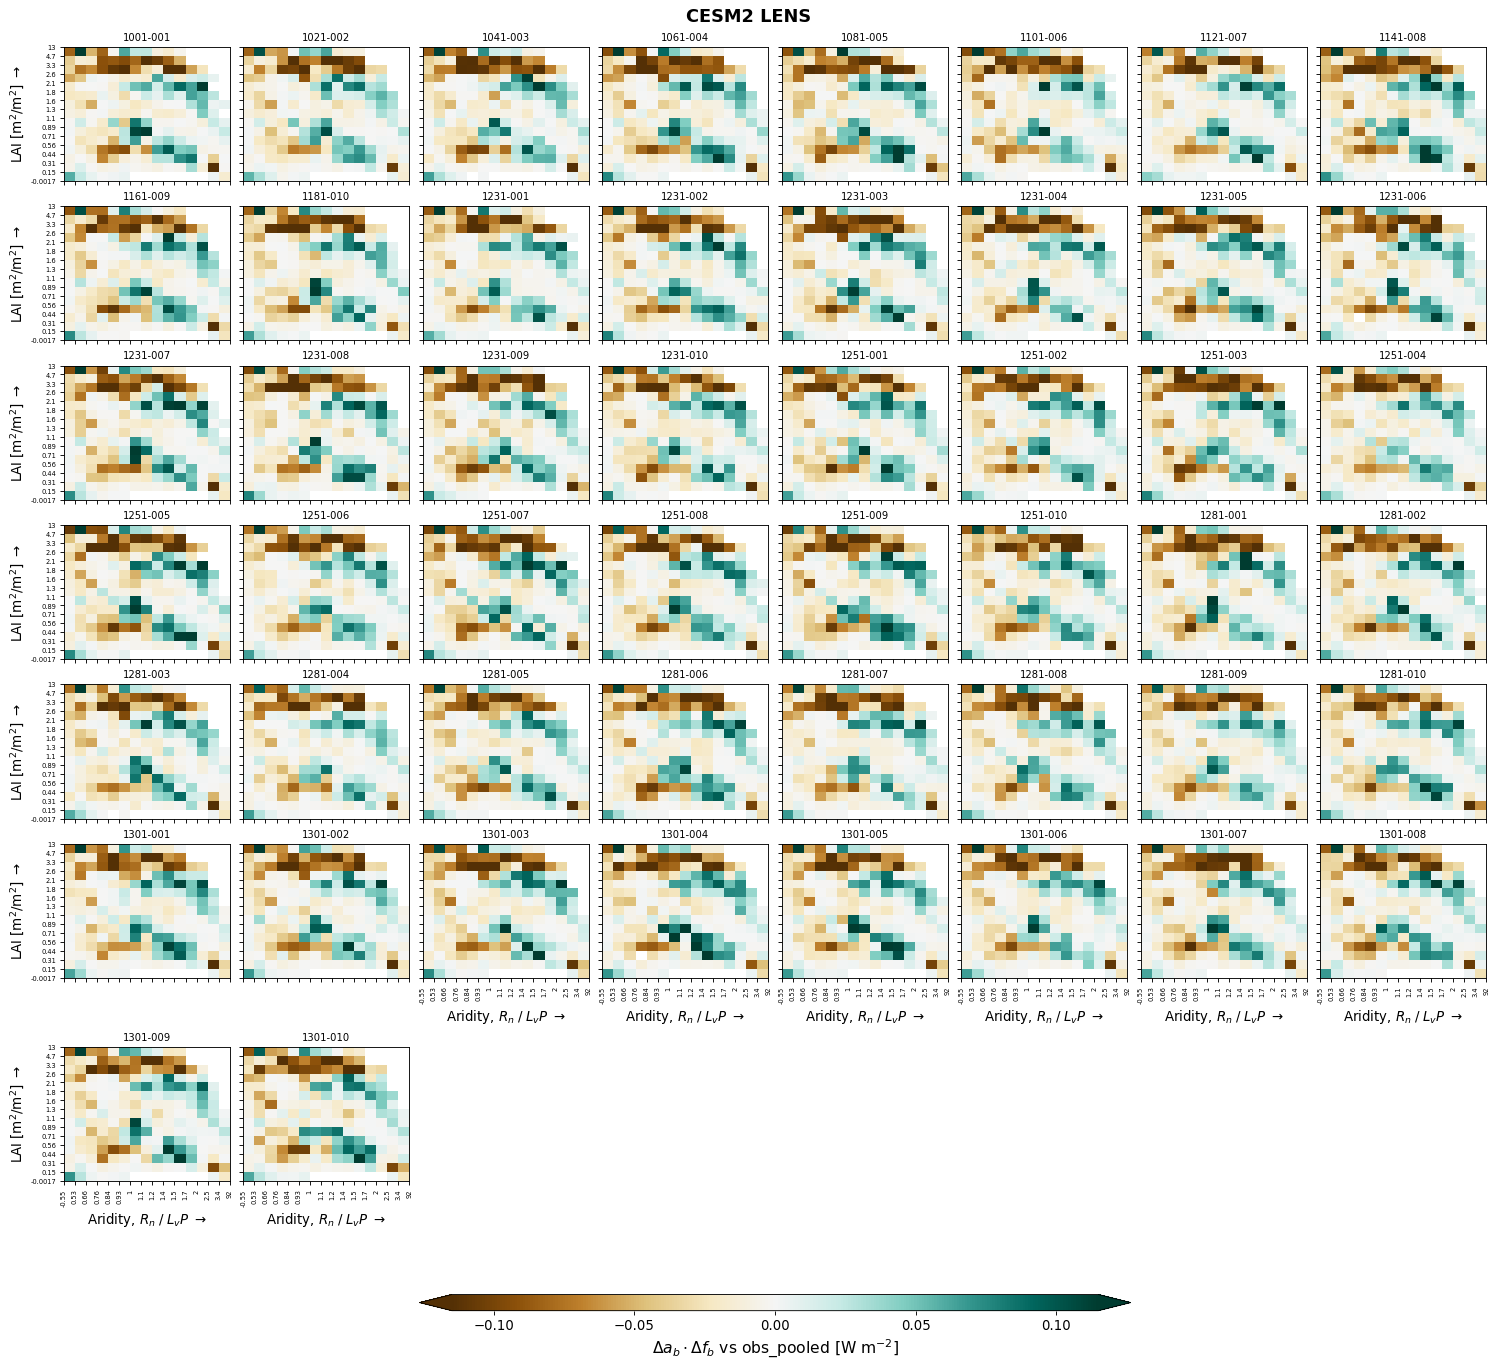

In [18]:
for f in DECOMP_FAMILIES:
    member_panels(members[f]["INTERACTION"], f, TERMS["INTERACTION"] + " vs obs_pooled [W m$^{-2}$]",
                  cmap=CMAP,
                #   vmin=-0.5, vmax=0.5,
                  robust=True,
                )
    plt.show()

### S1.4. Histograms of the terms
Each member against `obs_pooled`: the histogram of $\Delta a_b \cdot f_b$, $a_b \cdot \Delta f_b$ and $\Delta a_b \cdot \Delta f_b$ over its bins on the common support (3.1 for one member), y-axis the number of bins, with the skewness of each term in the panel's legend. The skewness (skew) of each term is the Fisher-Pearson coefficient (`scipy.stats.skew`) of its values over the bins, each bin counting once as in the histogram: positive when the bins far from 0 are mostly positive. One figure per family, with the histogram edges and axes shared by its members (symmetric, one bin centered on 0, covering every member and term of the family). `LOG_Y` is that of 3.1. Needs the 3.1 cell to be run first (`flatten_bins`, `TERM_COLORS`, `LOG_Y`).

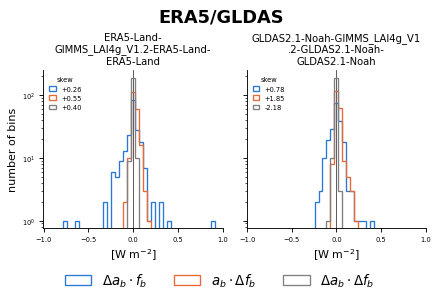

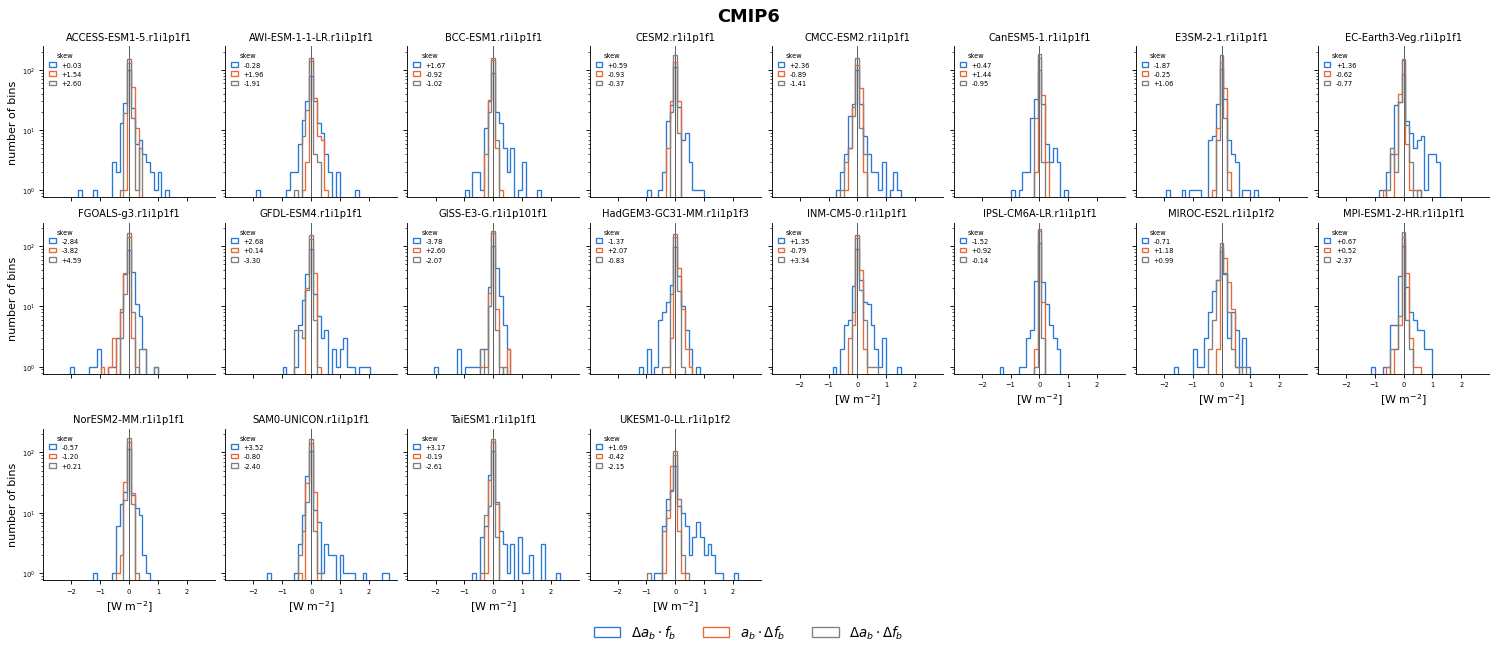

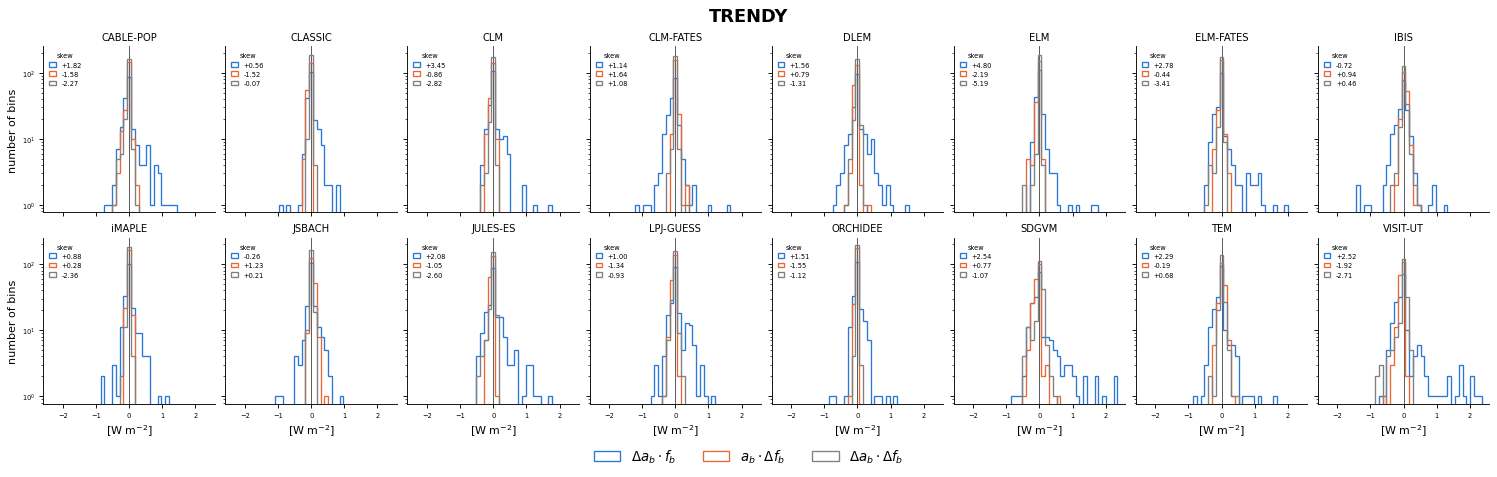

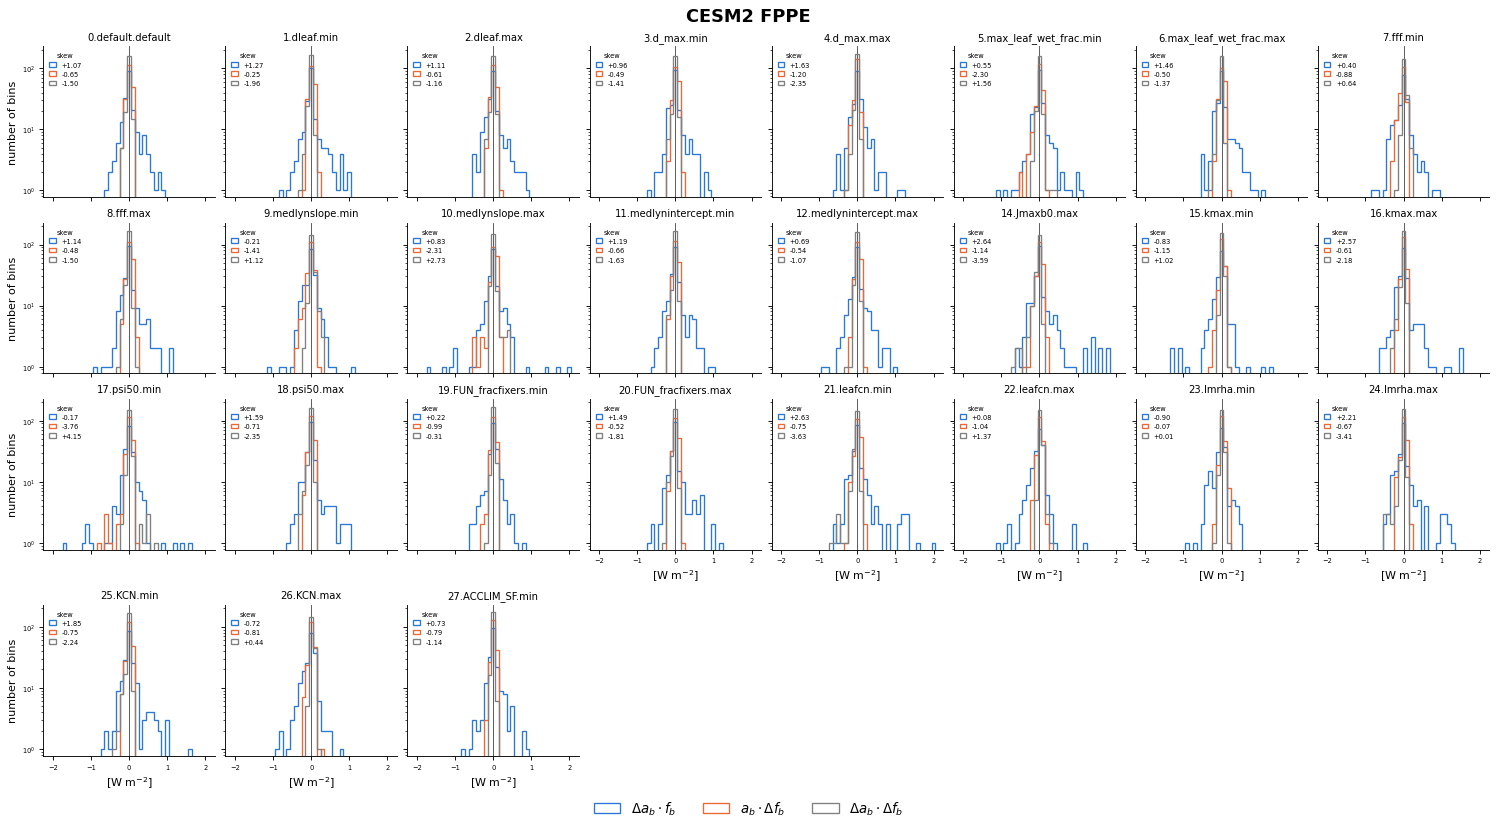

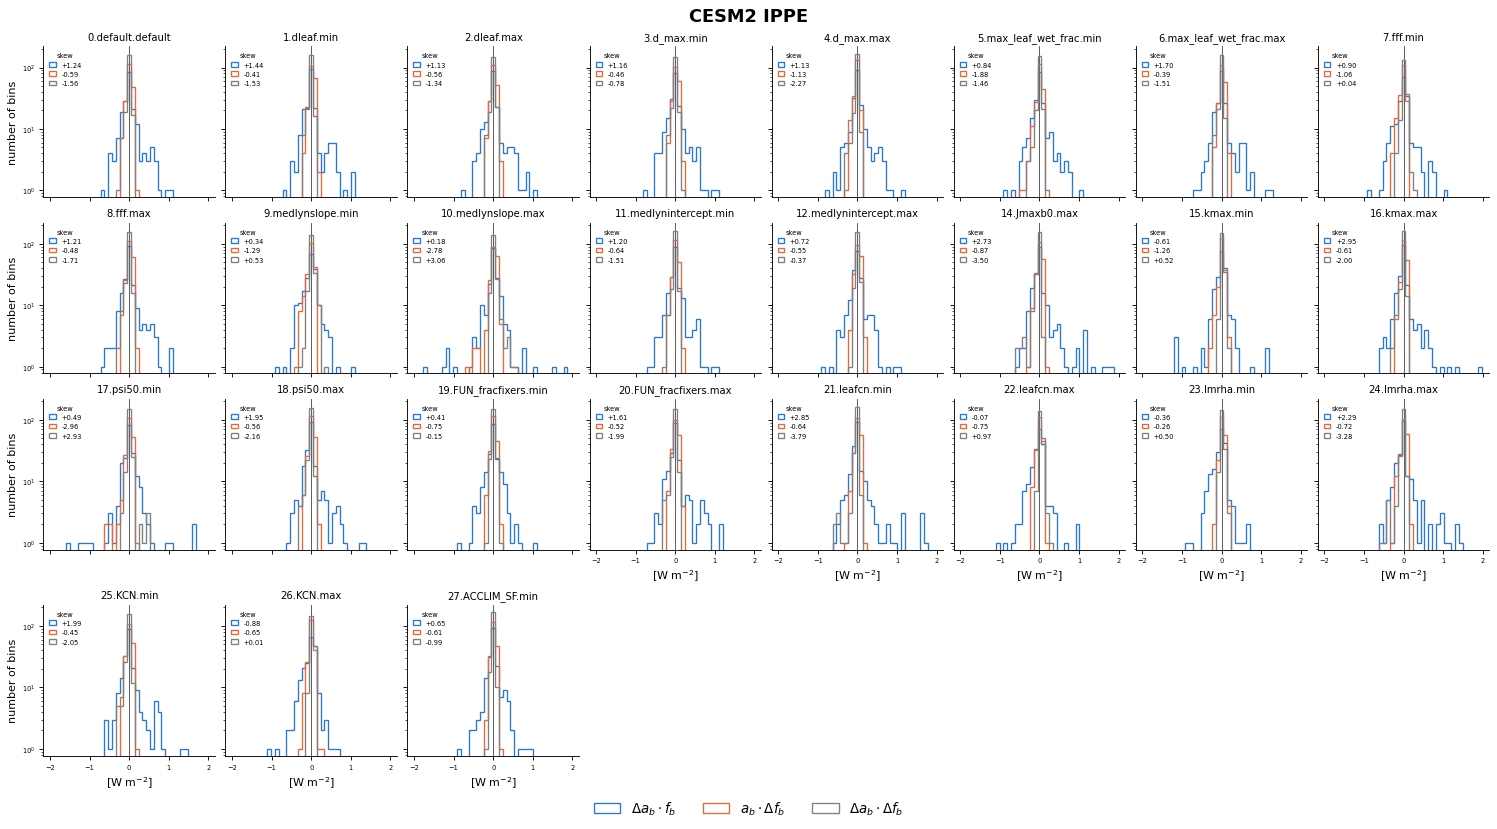

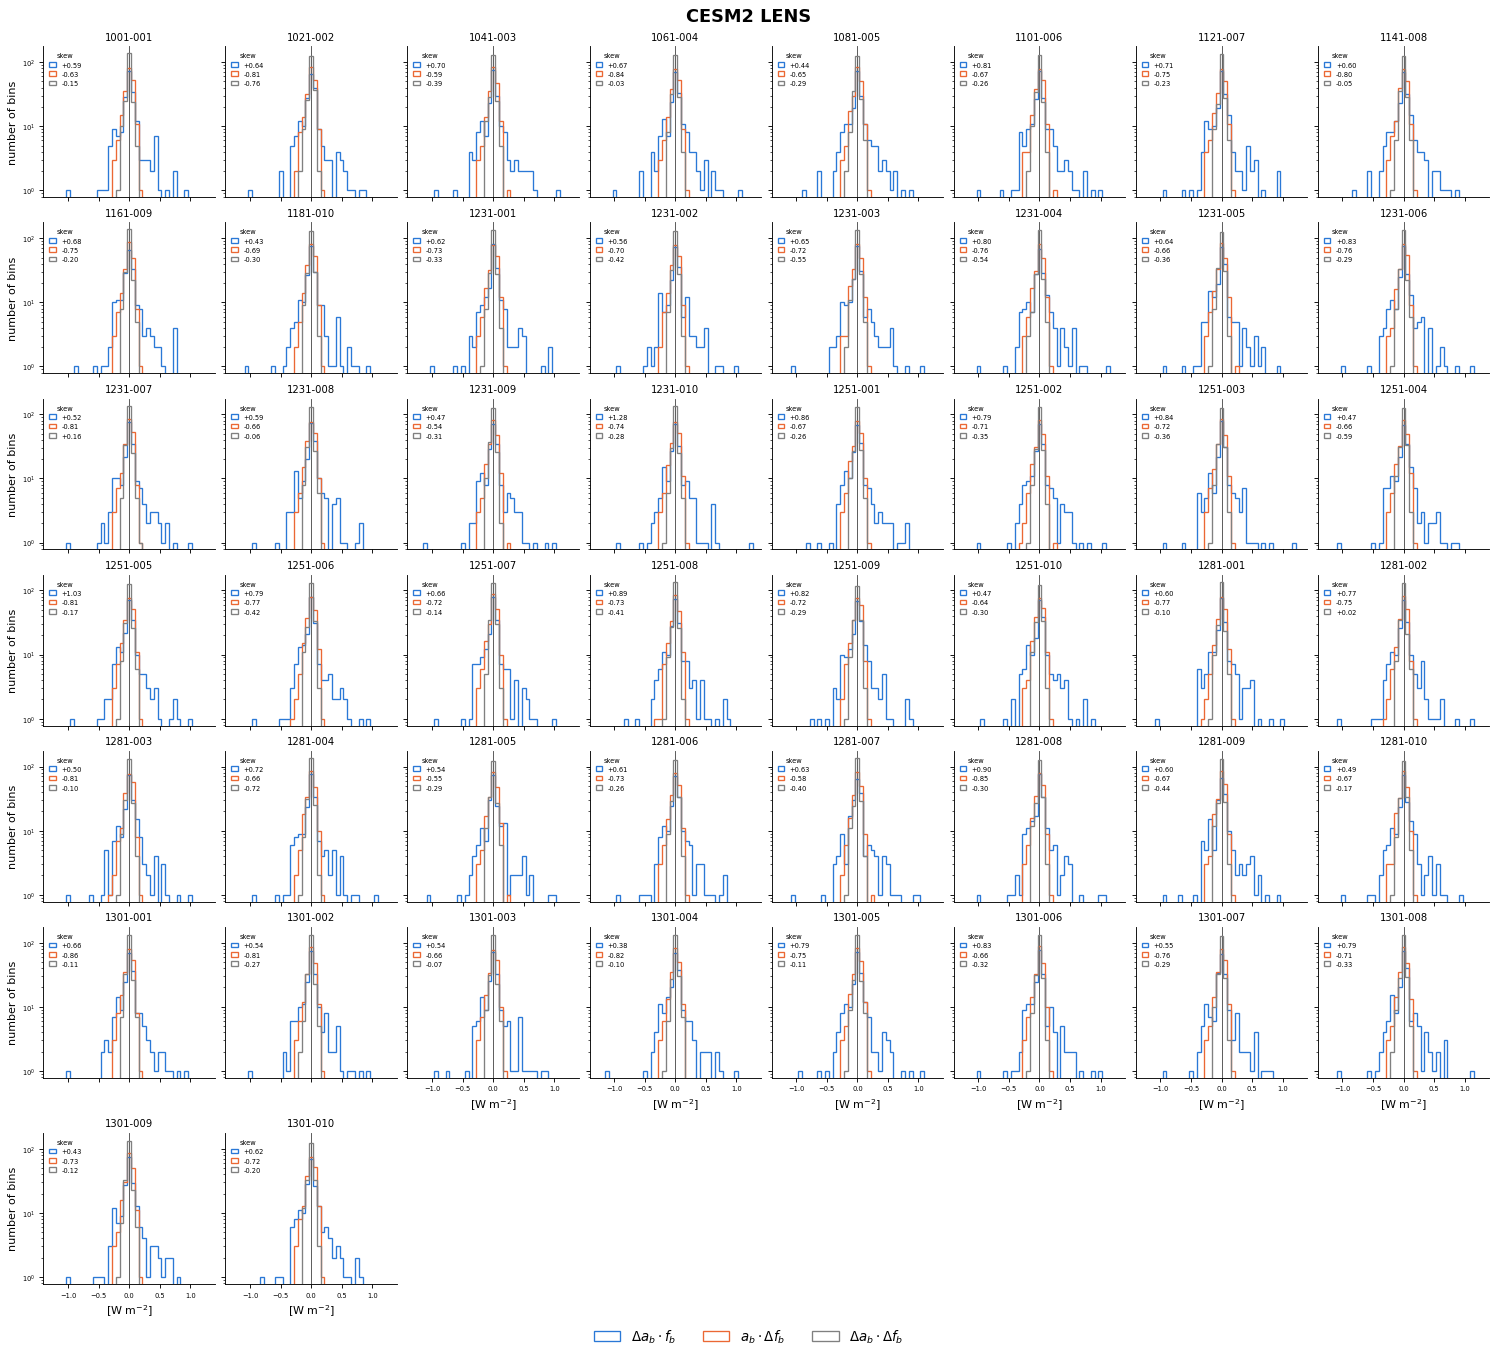

In [16]:
def member_hist_panels(ds, family, edges, ncols=8, panel_size=2.2):
    # One panel per dataset of `ds`, `ncols` panels per row, each with the histograms of the three terms over
    # its bins (`edges`) and their skewness, a legend of the terms below (obs titled by ET product, TRENDY by model, the others by member).
    # Returns the figure.
    n = ds.sizes["dataset"]
    ncols = min(ncols, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        sharex=True,
        sharey=True,
        figsize=(panel_size * ncols + 1, panel_size * nrows + 1.5),
        layout="constrained",
        dpi=DPI,
        squeeze=False,
    )
    axs = axes.ravel()
    titles = (ds["et_product"].values if family == "obs" else ds["source"].values if family == "trendy_s3"
              else [str(d).split(".", 1)[1] for d in ds["dataset"].values])
    for i in range(n):
        handles, skews = [], []
        for t, label in TERMS.items():
            v = flatten_bins(ds[t].isel(dataset=i))
            _, _, patches = axs[i].hist(v, bins=edges, histtype="step", linewidth=1.2, color=TERM_COLORS[t],
                                        label=label)
            handles.append(patches[0])
            skews.append(f"{stats.skew(v):+.2f}")
        # Skewness of each term, by its line color
        axs[i].legend(handles, skews, title="skew", title_fontsize=6, loc="upper left", fontsize=6,
                      handlelength=1, frameon=False)
        if LOG_Y:
            axs[i].set_yscale("log")
        axs[i].axvline(0, color="0.3", linewidth=0.8, zorder=0)
        axs[i].spines[["top", "right"]].set_visible(False)
        axs[i].tick_params(labelsize=6)
        axs[i].set_title(textwrap.fill(str(titles[i]), 28), fontsize=9)  # long titles on several lines
        if i % ncols == 0:
            axs[i].set_ylabel("number of bins", fontsize=10)
        if i + ncols >= n:
            axs[i].set_xlabel("[W m$^{-2}$]", fontsize=10)
            axs[i].tick_params(labelbottom=True)
    # Unused panels of the last row
    for ax in axs[n:]:
        ax.remove()

    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncols=len(TERMS), fontsize=12,
               frameon=False)
    fig.suptitle(FAMILY_KWARGS["labels"][family], fontsize=16, fontweight="bold")
    return fig


for f in DECOMP_FAMILIES:
    # Histogram edges of this family: covering every member and term
    lim = max(float(abs(members[f][t]).max()) for t in TERMS)
    member_hist_panels(members[f], f, np.linspace(-lim, lim, 42))
    plt.show()